# Most and Least Relevant Industries

| Item | Description |
|---|---|
| Goal | Figure C of the plan: for each relevance measure, one single-panel figure with one horizontal bar per industry (NAICS two-digit sector) showing the sector mean of the firm score minus the mean over all sample firms, so that zero is the sample mean, bars to the right are sectors above it and bars to the left below it, with an error bar for the variation of the firm scores within the sector. Sectors are sorted from the most to the least relevant. |
| Input | `output/T3.8.3/firm_relevance_scores_wide.csv` (T3.8.3); the CRSP-Compustat link file `crsp_compustat_link.dta` in the source data folder for each firm's Compustat NAICS code. |
| Output | `output/T3.9.3/firm_industries.csv`: one row per firm with its NAICS code and sector. `output/T3.9.3/sector_means.csv`: one row per sector and measure. `output/T3.9.3/fig_industries_<method>_<vector>_<measure>.{png,svg,pdf}`, one figure per measure. |
| Unit | A NAICS two-digit sector; the firm is the unit the sector mean is taken over. Firms are those of the three-year sample (fiscal 2010, 2015, 2020; 841 firms). |
| Industry | Compustat's NAICS code for the firm (one code per gvkey in the link file), cut to two digits. The sectors that NAICS spreads over several two-digit codes are merged: 31 to 33 manufacturing, 44 to 45 retail trade, 48 to 49 transportation and warehousing. Sectors with fewer than `MIN_FIRMS` firms are left out of the figures and named in the Notes. |
| Measures | The ten measures of T3.8.3. For the binary measures the sector mean is the share of the sector's firms with at least one matched sentence. The error bar spans `ERROR_BAR` on each side of the sector mean: `sd`, one standard deviation of the firm scores within the sector (the within-industry variation), or `ci95`, a 95 percent confidence interval of the sector mean. |
| Style | S3: 9 by 6 inches, Times, 0.5 cm margins, one series so no legend, GREY bars with BLUE error bars so the variation stands out, a solid BLACK zero line, no text inside the plot, title and notes in Markdown below. |

See `Topic Relevance Rebuild Plan.md` in the TEMP folder for the surrounding steps and `T3.8.3` for what each measure is.


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


## Step 2. Define file locations, the sectors, and the measures to plot


In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SOURCE_DATA_FOLDER = Path("/project2/mmiric_1435/acroh/llm_method/data")
NOTEBOOK_SUBFOLDER = Path("T3 - Topic Relevance and Corporate Disclosure/TEMP")
NOTEBOOK_NAME = "T3.9.3"  # the identifier names this notebook's output folder
TEMP_OUTPUT = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output"
OUTPUT_FOLDER = TEMP_OUTPUT / NOTEBOOK_NAME
SCORES_FILE = TEMP_OUTPUT / "T3.8.3/firm_relevance_scores_wide.csv"
LINK_FILE = SOURCE_DATA_FOLDER / "interim/repo_data/raw/01_firm_id/crsp_compustat_link.dta"

SAMPLE = "three_years"
MIN_FIRMS = 5  # a sector with fewer firms is left out of the figures
ERROR_BAR = "sd"  # "sd": one standard deviation of the firm scores within the sector on each side; "ci95": 95 percent confidence interval of the sector mean
ZERO_LINE_WIDTH = 0.8 / 3  # S3 zero line
NAICS_SECTORS = {  # two-digit code -> sector name; codes that share a sector map to the same name
    "11": "Agriculture, forestry, fishing and hunting", "21": "Mining, quarrying, and oil and gas extraction", "22": "Utilities", "23": "Construction",
    "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing", "42": "Wholesale trade", "44": "Retail trade", "45": "Retail trade",
    "48": "Transportation and warehousing", "49": "Transportation and warehousing", "51": "Information", "52": "Finance and insurance",
    "53": "Real estate and rental and leasing", "54": "Professional, scientific, and technical services", "55": "Management of companies and enterprises",
    "56": "Administrative and support and waste management", "61": "Educational services", "62": "Health care and social assistance",
    "71": "Arts, entertainment, and recreation", "72": "Accommodation and food services", "81": "Other services", "92": "Public administration",
    "99": "Unclassified",
}
VECTOR_WORDS = {"definition": "the topic definition", "centroid": "the statement centroid", "policy_summary": "the policy summary"}
# measure_id -> (file stem, short name of the firm score, unit, one-sentence description of the firm score for the Notes)
MEASURES = {
    "sentences | definition | binary": ("fig_industries_sentences_definition_binary", "share of firms with a sentence at or above the definition threshold", "share of firms",
        "an indicator for the firm having at least one Item 1 sentence whose cosine with the topic definition is at or above 0.67, so the sector mean is the share of such firms"),
    "sentences | definition | share": ("fig_industries_sentences_definition_share", "share of Item 1 sentences at or above the definition threshold", "share",
        "the share of the firm's Item 1 sentences whose cosine with the topic definition is at or above 0.67"),
    "sentences | centroid | binary": ("fig_industries_sentences_centroid_binary", "share of firms with a sentence at or above the centroid threshold", "share of firms",
        "an indicator for the firm having at least one Item 1 sentence whose cosine with the statement centroid is at or above 0.75, so the sector mean is the share of such firms"),
    "sentences | centroid | share": ("fig_industries_sentences_centroid_share", "share of Item 1 sentences at or above the centroid threshold", "share",
        "the share of the firm's Item 1 sentences whose cosine with the statement centroid is at or above 0.75"),
    "summaries | definition | firm_summary": ("fig_industries_summaries_definition_firm_summary", "cosine between the firm summary and the topic definition", "cosine",
        "the cosine between the firm's Item 1 summary and the topic definition"),
    "summaries | definition | yearly_mean": ("fig_industries_summaries_definition_yearly_mean", "mean cosine between the yearly summaries and the topic definition", "cosine",
        "the firm's average cosine between its yearly Item 1 summaries and the topic definition"),
    "summaries | centroid | firm_summary": ("fig_industries_summaries_centroid_firm_summary", "cosine between the firm summary and the statement centroid", "cosine",
        "the cosine between the firm's Item 1 summary and the centroid of the Topic 68 hearing statements"),
    "summaries | centroid | yearly_mean": ("fig_industries_summaries_centroid_yearly_mean", "mean cosine between the yearly summaries and the statement centroid", "cosine",
        "the firm's average cosine between its yearly Item 1 summaries and the centroid of the Topic 68 hearing statements"),
    "summaries | policy_summary | firm_summary": ("fig_industries_summaries_policy_summary_firm_summary", "cosine between the firm summary and the policy summary", "cosine",
        "the cosine between the firm's Item 1 summary and the policy summary of the Topic 68 hearing statements"),
    "summaries | policy_summary | yearly_mean": ("fig_industries_summaries_policy_summary_yearly_mean", "mean cosine between the yearly summaries and the policy summary", "cosine",
        "the firm's average cosine between its yearly Item 1 summaries and the policy summary of the Topic 68 hearing statements"),
}
SOURCE = "10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")


Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.3


## Step 3. Figure style

The S3 settings: canvas, font, colors, horizontal background lines only.


In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
EXPORT_DPI = 300

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 4. Attach a NAICS sector to every firm

The link file carries one Compustat NAICS code per gvkey (checked); the first two digits give the sector, merged where NAICS splits a sector over several codes. Every firm of the sample must get a code.


In [4]:
wide = pd.read_csv(SCORES_FILE, dtype={"gvkey": str})
wide = wide.loc[wide["sample"].eq(SAMPLE)].reset_index(drop=True)
missing_columns = [m for m in MEASURES if m not in wide.columns]
assert not missing_columns, missing_columns

link = pd.read_stata(LINK_FILE, columns=["GVKEY", "naics"])
link["gvkey"] = link["GVKEY"].astype(str).str.zfill(6)
link["naics"] = link["naics"].astype(str).str.strip().replace({"": None, "nan": None})
link = link.dropna(subset=["naics"])
assert link.groupby("gvkey")["naics"].nunique().le(1).all(), "a gvkey with two NAICS codes"
naics = link.drop_duplicates("gvkey").set_index("gvkey")["naics"]
wide["naics"] = wide["gvkey"].map(naics)
assert wide["naics"].notna().all(), f"{int(wide['naics'].isna().sum())} firms without a NAICS code"
wide["naics2"] = wide["naics"].str[:2]
assert wide["naics2"].isin(NAICS_SECTORS).all(), sorted(set(wide["naics2"]) - set(NAICS_SECTORS))
wide["sector"] = wide["naics2"].map(NAICS_SECTORS)
industries = wide[["gvkey", "conm", "naics", "naics2", "sector"]].sort_values("gvkey")
industries.to_csv(OUTPUT_FOLDER / "firm_industries.csv", index=False)
sector_sizes = wide.groupby("sector").size().sort_values(ascending=False)
print(f"Firms: {len(wide):,}; sectors: {len(sector_sizes)}; sectors with fewer than {MIN_FIRMS} firms (left out of the figures): "
      f"{', '.join(f'{s} ({n})' for s, n in sector_sizes[sector_sizes < MIN_FIRMS].items()) or 'none'}")
display(sector_sizes.rename("firms").to_frame().T)


Firms: 841; sectors: 19; sectors with fewer than 5 firms (left out of the figures): Arts, entertainment, and recreation (4), Unclassified (4), Educational services (3), Other services (2), Agriculture, forestry, fishing and hunting (2)


sector,Manufacturing,Finance and insurance,Information,Retail trade,"Mining, quarrying, and oil and gas extraction",Real estate and rental and leasing,Utilities,"Professional, scientific, and technical services",Transportation and warehousing,Wholesale trade,Accommodation and food services,Administrative and support and waste management,Health care and social assistance,Construction,"Arts, entertainment, and recreation",Unclassified,Educational services,Other services,"Agriculture, forestry, fishing and hunting"
firms,330,113,89,53,44,42,36,27,25,18,15,13,11,10,4,4,3,2,2


## Step 5. Compute the sector means, the sample means, and the within-sector variation

For every measure: the mean over all sample firms, the mean and standard deviation of the firm scores within each sector, the number of firms, and the sector mean minus the sample mean, which is what the bars show. Saved as one long table.


In [5]:
measure_columns = list(MEASURES)
sample_mean = wide[measure_columns].mean()
sector_stats = wide.groupby("sector")[measure_columns].agg(["mean", "std"])
sector_stats.columns = [f"{measure}||{stat}" for measure, stat in sector_stats.columns]
rows = []
for measure_id in measure_columns:
    for sector in sector_stats.index:
        n = int(sector_sizes[sector])
        mean, sd = sector_stats.loc[sector, f"{measure_id}||mean"], sector_stats.loc[sector, f"{measure_id}||std"]
        rows.append({"measure_id": measure_id, "sector": sector, "n_firms": n, "sector_mean": mean, "sector_sd": sd, "sample_mean": sample_mean[measure_id],
                     "difference_from_sample_mean": mean - sample_mean[measure_id], "ci95_half_width": 1.96 * sd / np.sqrt(n) if n > 1 else np.nan})
long = pd.DataFrame(rows)
long.sort_values(["measure_id", "sector_mean"], ascending=[True, False]).to_csv(OUTPUT_FOLDER / "sector_means.csv", index=False, float_format="%.6f")
print(f"Saved: {OUTPUT_FOLDER / 'sector_means.csv'} ({len(long):,} rows = {sector_stats.shape[0]} sectors x {len(measure_columns)} measures)")
print("Sample means:")
display(sample_mean.round(4).to_frame("mean over all firms").T)
example = long.loc[long["measure_id"].eq("sentences | definition | binary")].sort_values("sector_mean", ascending=False)
display(example[["sector", "n_firms", "sector_mean", "sector_sd", "difference_from_sample_mean", "ci95_half_width"]].round(4).reset_index(drop=True))


Saved: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.3/sector_means.csv (190 rows = 19 sectors x 10 measures)
Sample means:


,sentences | definition | binary,sentences | definition | share,sentences | centroid | binary,sentences | centroid | share,summaries | definition | firm_summary,summaries | definition | yearly_mean,summaries | centroid | firm_summary,summaries | centroid | yearly_mean,summaries | policy_summary | firm_summary,summaries | policy_summary | yearly_mean
mean over all firms,0.2283,0.0012,0.1926,0.0008,0.4313,0.4333,0.5032,0.5011,0.5143,0.5078


,sector,n_firms,sector_mean,sector_sd,difference_from_sample_mean,ci95_half_width
0,Health care and social assistance,11,0.7273,0.4671,0.4990,0.2760
1,Educational services,3,0.6667,0.5774,0.4384,0.6533
2,Finance and insurance,113,0.5752,0.4965,0.3469,0.0915
3,Other services,2,0.5000,0.7071,0.2717,0.9800
4,Information,89,0.4719,0.5020,0.2436,0.1043
5,Administrative and support and waste management,13,0.4615,0.5189,0.2332,0.2821
6,Accommodation and food services,15,0.3333,0.4880,0.1050,0.2469
7,Wholesale trade,18,0.3333,0.4851,0.1050,0.2241
8,"Professional, scientific, and technical services",27,0.2963,0.4653,0.0680,0.1755
9,"Arts, entertainment, and recreation",4,0.2500,0.5000,0.0217,0.4900


## Step 6. Draw one figure per measure

Sectors with at least `MIN_FIRMS` firms, sorted from the highest to the lowest sector mean. Each GREY bar runs from zero, the sample mean, to the sector mean minus the sample mean; the BLUE error bar spans the within-sector variation on each side of the bar end; a solid BLACK line marks zero. The number of firms is in the tick label. One series, so no legend; positions are measured after drawing so that the Y-title starts 0.5 cm from the left edge and the X-title ends 0.5 cm above the bottom edge.


In [6]:
plotted_sectors = sector_sizes.index[sector_sizes >= MIN_FIRMS]
left_out = sector_sizes[sector_sizes < MIN_FIRMS]
figure_records = []
for figure_number, (measure_id, (figure_name, short_name, unit, description)) in enumerate(MEASURES.items(), start=1):
    part = long.loc[long["measure_id"].eq(measure_id) & long["sector"].isin(plotted_sectors)].sort_values("sector_mean", ascending=False)
    half_width = part["sector_sd"] if ERROR_BAR == "sd" else part["ci95_half_width"]
    labels = [f"{sector} ({n})" for sector, n in zip(part["sector"], part["n_firms"])]
    positions = np.arange(len(part))[::-1]  # highest sector at the top

    figure, axis = plt.subplots()
    figure.subplots_adjust(left=0.42, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.17)
    axis.barh(positions, part["difference_from_sample_mean"], color=GREY, height=0.7, zorder=2)
    axis.errorbar(part["difference_from_sample_mean"], positions, xerr=half_width, fmt="none", ecolor=BLUE, elinewidth=1.1, capsize=3, zorder=3)
    axis.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=4)
    axis.set_yticks(positions, labels=labels)
    axis.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
    reach = max(float((part["difference_from_sample_mean"].abs() + half_width.fillna(0)).max()), 1e-9)
    axis.set_xlim(-reach * 1.05, reach * 1.05)
    axis.set_xlabel(f"Sector mean minus the sample mean of the\n{short_name} ({unit})")
    axis.set_ylabel("NAICS sector (number of firms)")
    axis.tick_params(axis="y", length=0, labelsize=10)
    axis.spines[["top", "right"]].set_visible(False)

    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    margin_pixels = MARGIN_INCHES * figure.dpi
    left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
    bottom_shift = (margin_pixels - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
    figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
    for extension in ["png", "svg", "pdf"]:
        figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
    plt.close(figure)

    method, vector, measure = [part_.strip() for part_ in measure_id.split("|")]
    error_words = ("one standard deviation of the firm scores within the sector on each side of the sector mean, the within-industry variation across firms"
                   if ERROR_BAR == "sd" else "a 95 percent confidence interval of the sector mean, 1.96 standard errors on each side")
    left_out_note = (f" Sectors with fewer than {MIN_FIRMS} firms are left out: " + "; ".join(f"{s_} ({int(n)} firms)" for s_, n in left_out.items()) + ".") if len(left_out) else ""
    notes = (f"Each bar is the sector mean minus the mean over all {len(wide):,} firms of the three-year sample (fiscal years 2010, 2015, and 2020) of the firm score, which is {description}, "
             f"compared with {VECTOR_WORDS[vector]} of Topic 68, consumer data privacy legislation. Zero is the sample mean, {sample_mean[measure_id]:.4f}; bars to the right are sectors above it and bars to the left sectors below it. "
             f"The error bar spans {error_words}. Sectors are the two-digit NAICS sectors of the firms' Compustat NAICS codes, with manufacturing (31 to 33), retail trade (44 to 45), "
             f"and transportation and warehousing (48 to 49) each taken as one sector; the number of firms in each sector is in parentheses.{left_out_note}")
    figure_records.append((figure_number, figure_name, measure_id, notes))
    print(f"Figure {figure_number}: {figure_name} ({len(part)} sectors; sample mean {sample_mean[measure_id]:.4f}; top {part['sector'].iloc[0]} {part['difference_from_sample_mean'].iloc[0]:+.4f}, bottom {part['sector'].iloc[-1]} {part['difference_from_sample_mean'].iloc[-1]:+.4f})")


Figure 1: fig_industries_sentences_definition_binary (14 sectors; sample mean 0.2283; top Health care and social assistance +0.4990, bottom Utilities -0.2005)


Figure 2: fig_industries_sentences_definition_share (14 sectors; sample mean 0.0012; top Administrative and support and waste management +0.0047, bottom Utilities -0.0011)


Figure 3: fig_industries_sentences_centroid_binary (14 sectors; sample mean 0.1926; top Health care and social assistance +0.3528, bottom Utilities -0.1926)


Figure 4: fig_industries_sentences_centroid_share (14 sectors; sample mean 0.0008; top Administrative and support and waste management +0.0024, bottom Utilities -0.0008)


Figure 5: fig_industries_summaries_definition_firm_summary (14 sectors; sample mean 0.4313; top Information +0.0186, bottom Mining, quarrying, and oil and gas extraction -0.0400)


Figure 6: fig_industries_summaries_definition_yearly_mean (14 sectors; sample mean 0.4333; top Information +0.0210, bottom Mining, quarrying, and oil and gas extraction -0.0488)


Figure 7: fig_industries_summaries_centroid_firm_summary (14 sectors; sample mean 0.5032; top Information +0.0246, bottom Mining, quarrying, and oil and gas extraction -0.0304)


Figure 8: fig_industries_summaries_centroid_yearly_mean (14 sectors; sample mean 0.5011; top Administrative and support and waste management +0.0257, bottom Mining, quarrying, and oil and gas extraction -0.0340)


Figure 9: fig_industries_summaries_policy_summary_firm_summary (14 sectors; sample mean 0.5143; top Information +0.0424, bottom Mining, quarrying, and oil and gas extraction -0.0517)


Figure 10: fig_industries_summaries_policy_summary_yearly_mean (14 sectors; sample mean 0.5078; top Information +0.0450, bottom Mining, quarrying, and oil and gas extraction -0.0558)


## Step 7. Show the figures

Title, image, Notes, and Source for each figure, in that order.


**Figure 1. Share of Firms with a Matched Sentence by NAICS Sector Relative to the Sample Mean, with the Definition Vector**

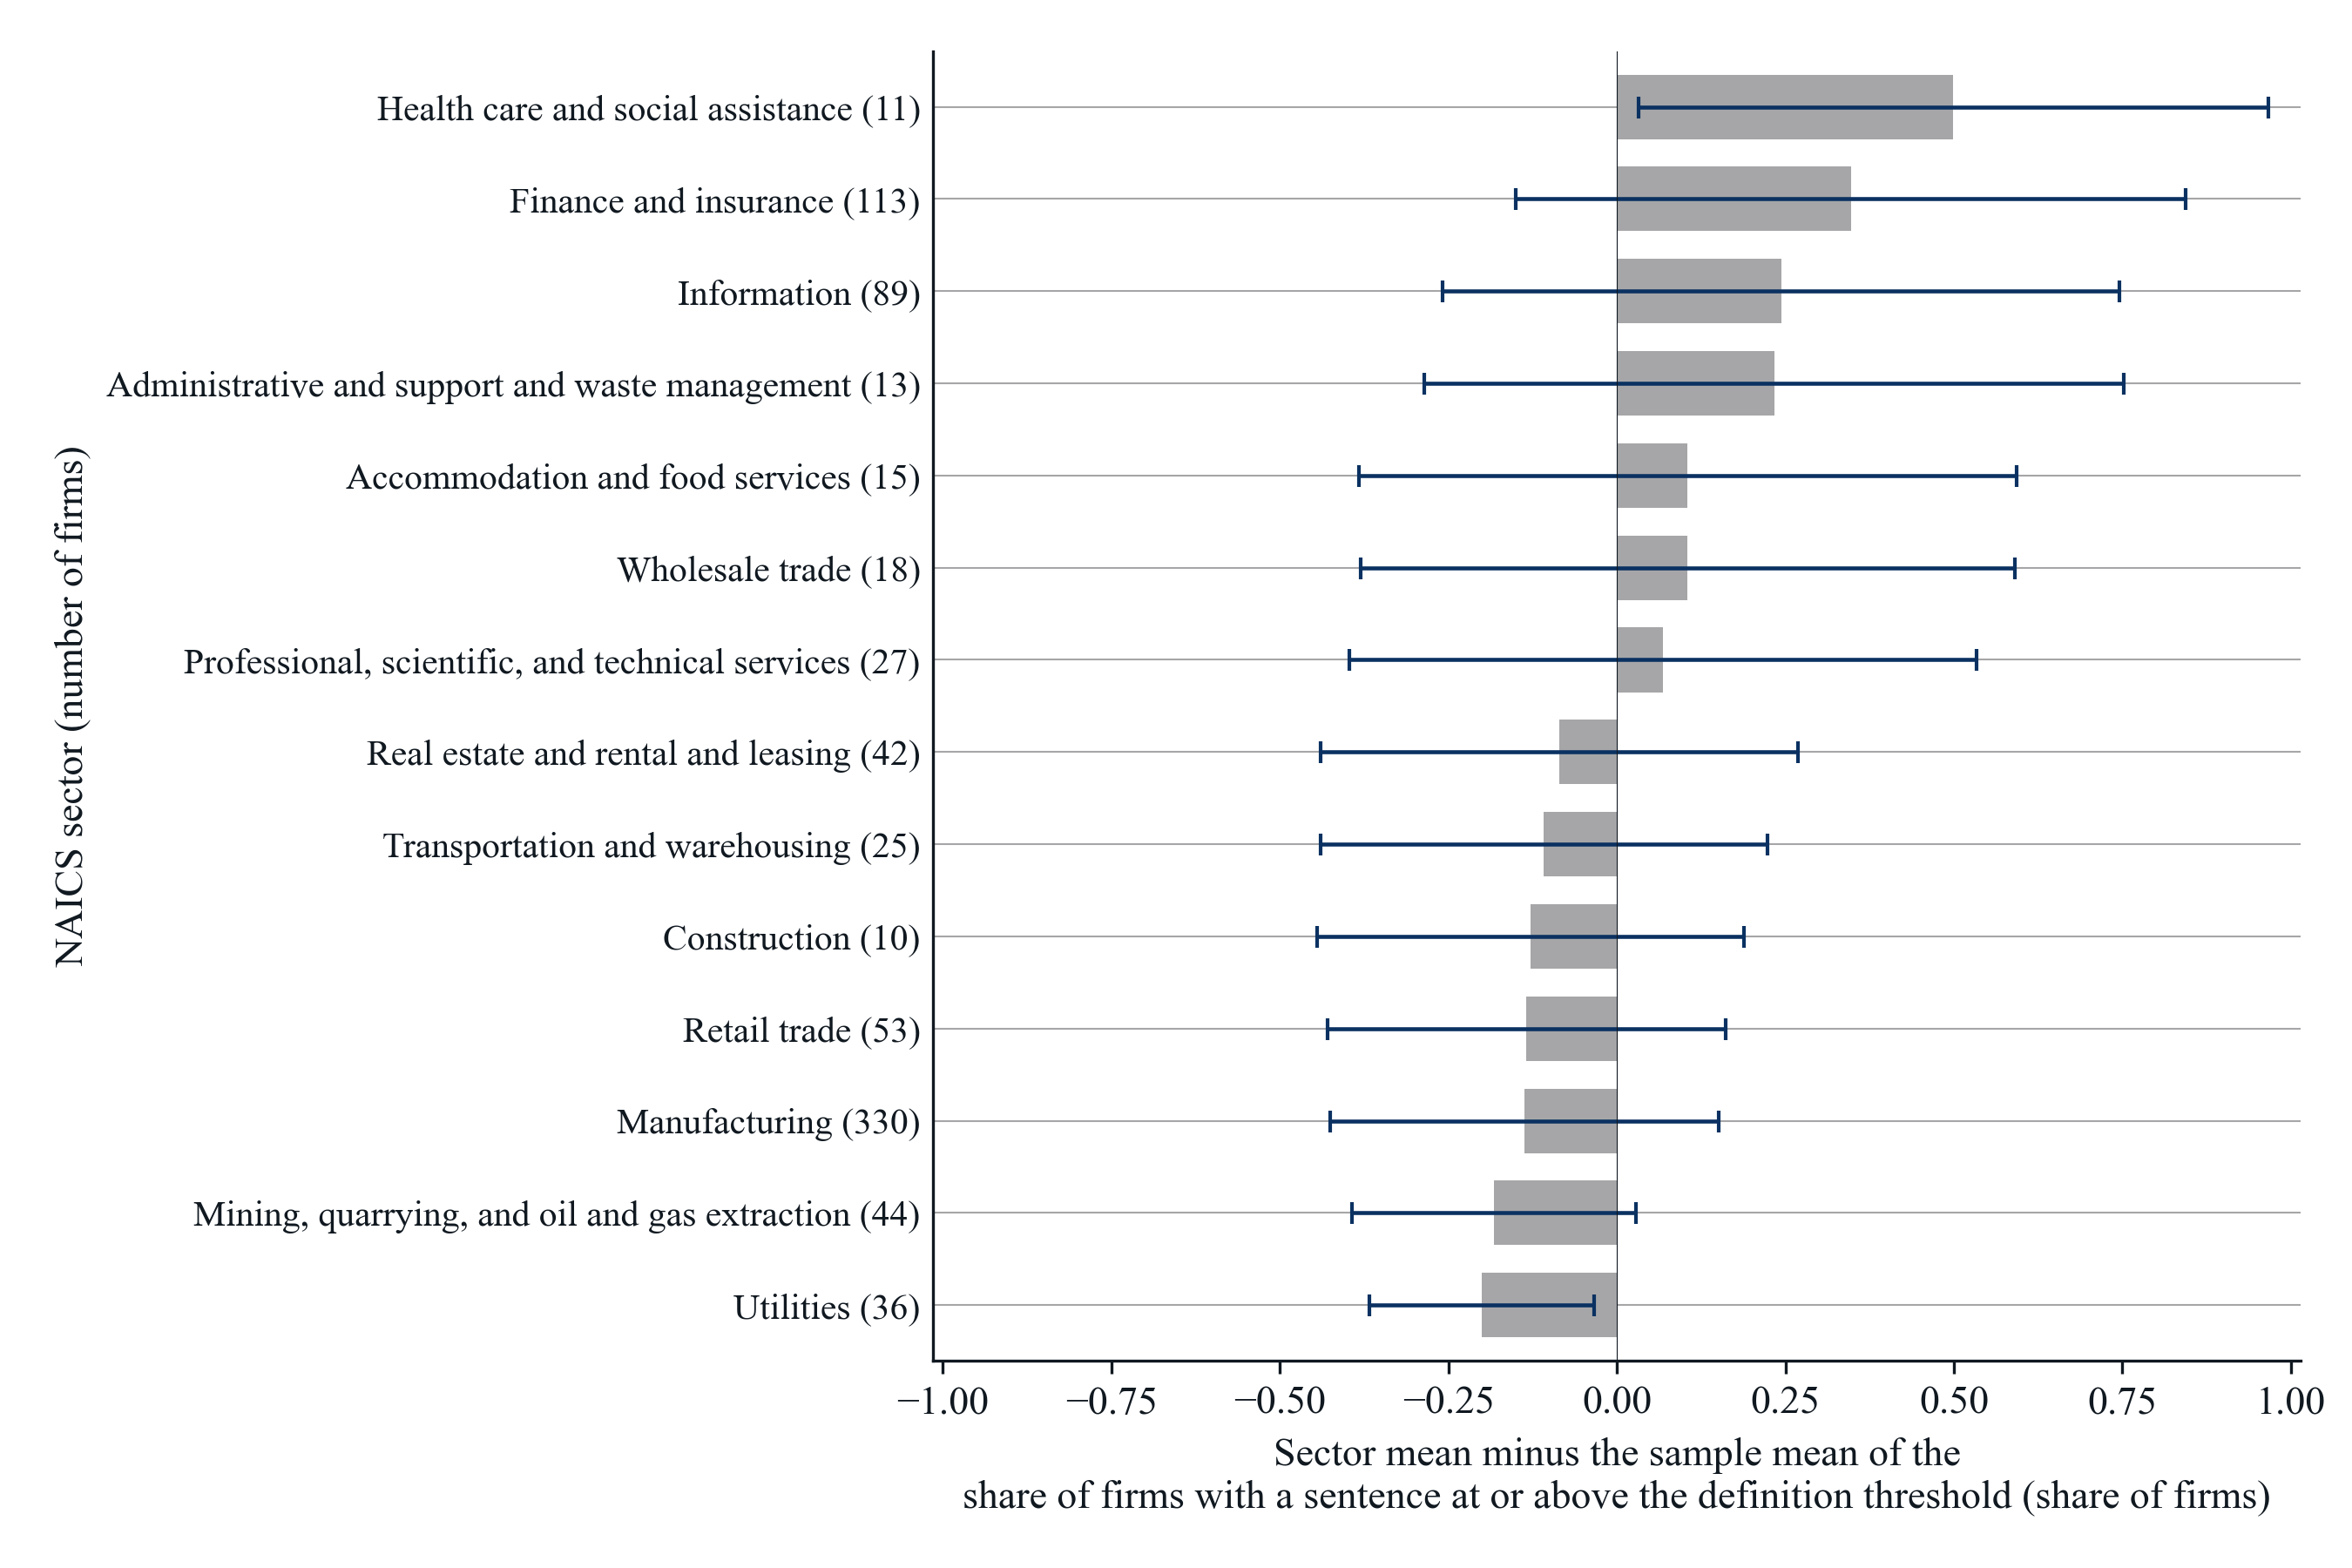

*Notes*: Each bar is the sector mean minus the mean over all 841 firms of the three-year sample (fiscal years 2010, 2015, and 2020) of the firm score, which is an indicator for the firm having at least one Item 1 sentence whose cosine with the topic definition is at or above 0.67, so the sector mean is the share of such firms, compared with the topic definition of Topic 68, consumer data privacy legislation. Zero is the sample mean, 0.2283; bars to the right are sectors above it and bars to the left sectors below it. The error bar spans one standard deviation of the firm scores within the sector on each side of the sector mean, the within-industry variation across firms. Sectors are the two-digit NAICS sectors of the firms' Compustat NAICS codes, with manufacturing (31 to 33), retail trade (44 to 45), and transportation and warehousing (48 to 49) each taken as one sector; the number of firms in each sector is in parentheses. Sectors with fewer than 5 firms are left out: Arts, entertainment, and recreation (4 firms); Unclassified (4 firms); Educational services (3 firms); Other services (2 firms); Agriculture, forestry, fishing and hunting (2 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 2. Share of Sentences by NAICS Sector Relative to the Sample Mean, with the Definition Vector**

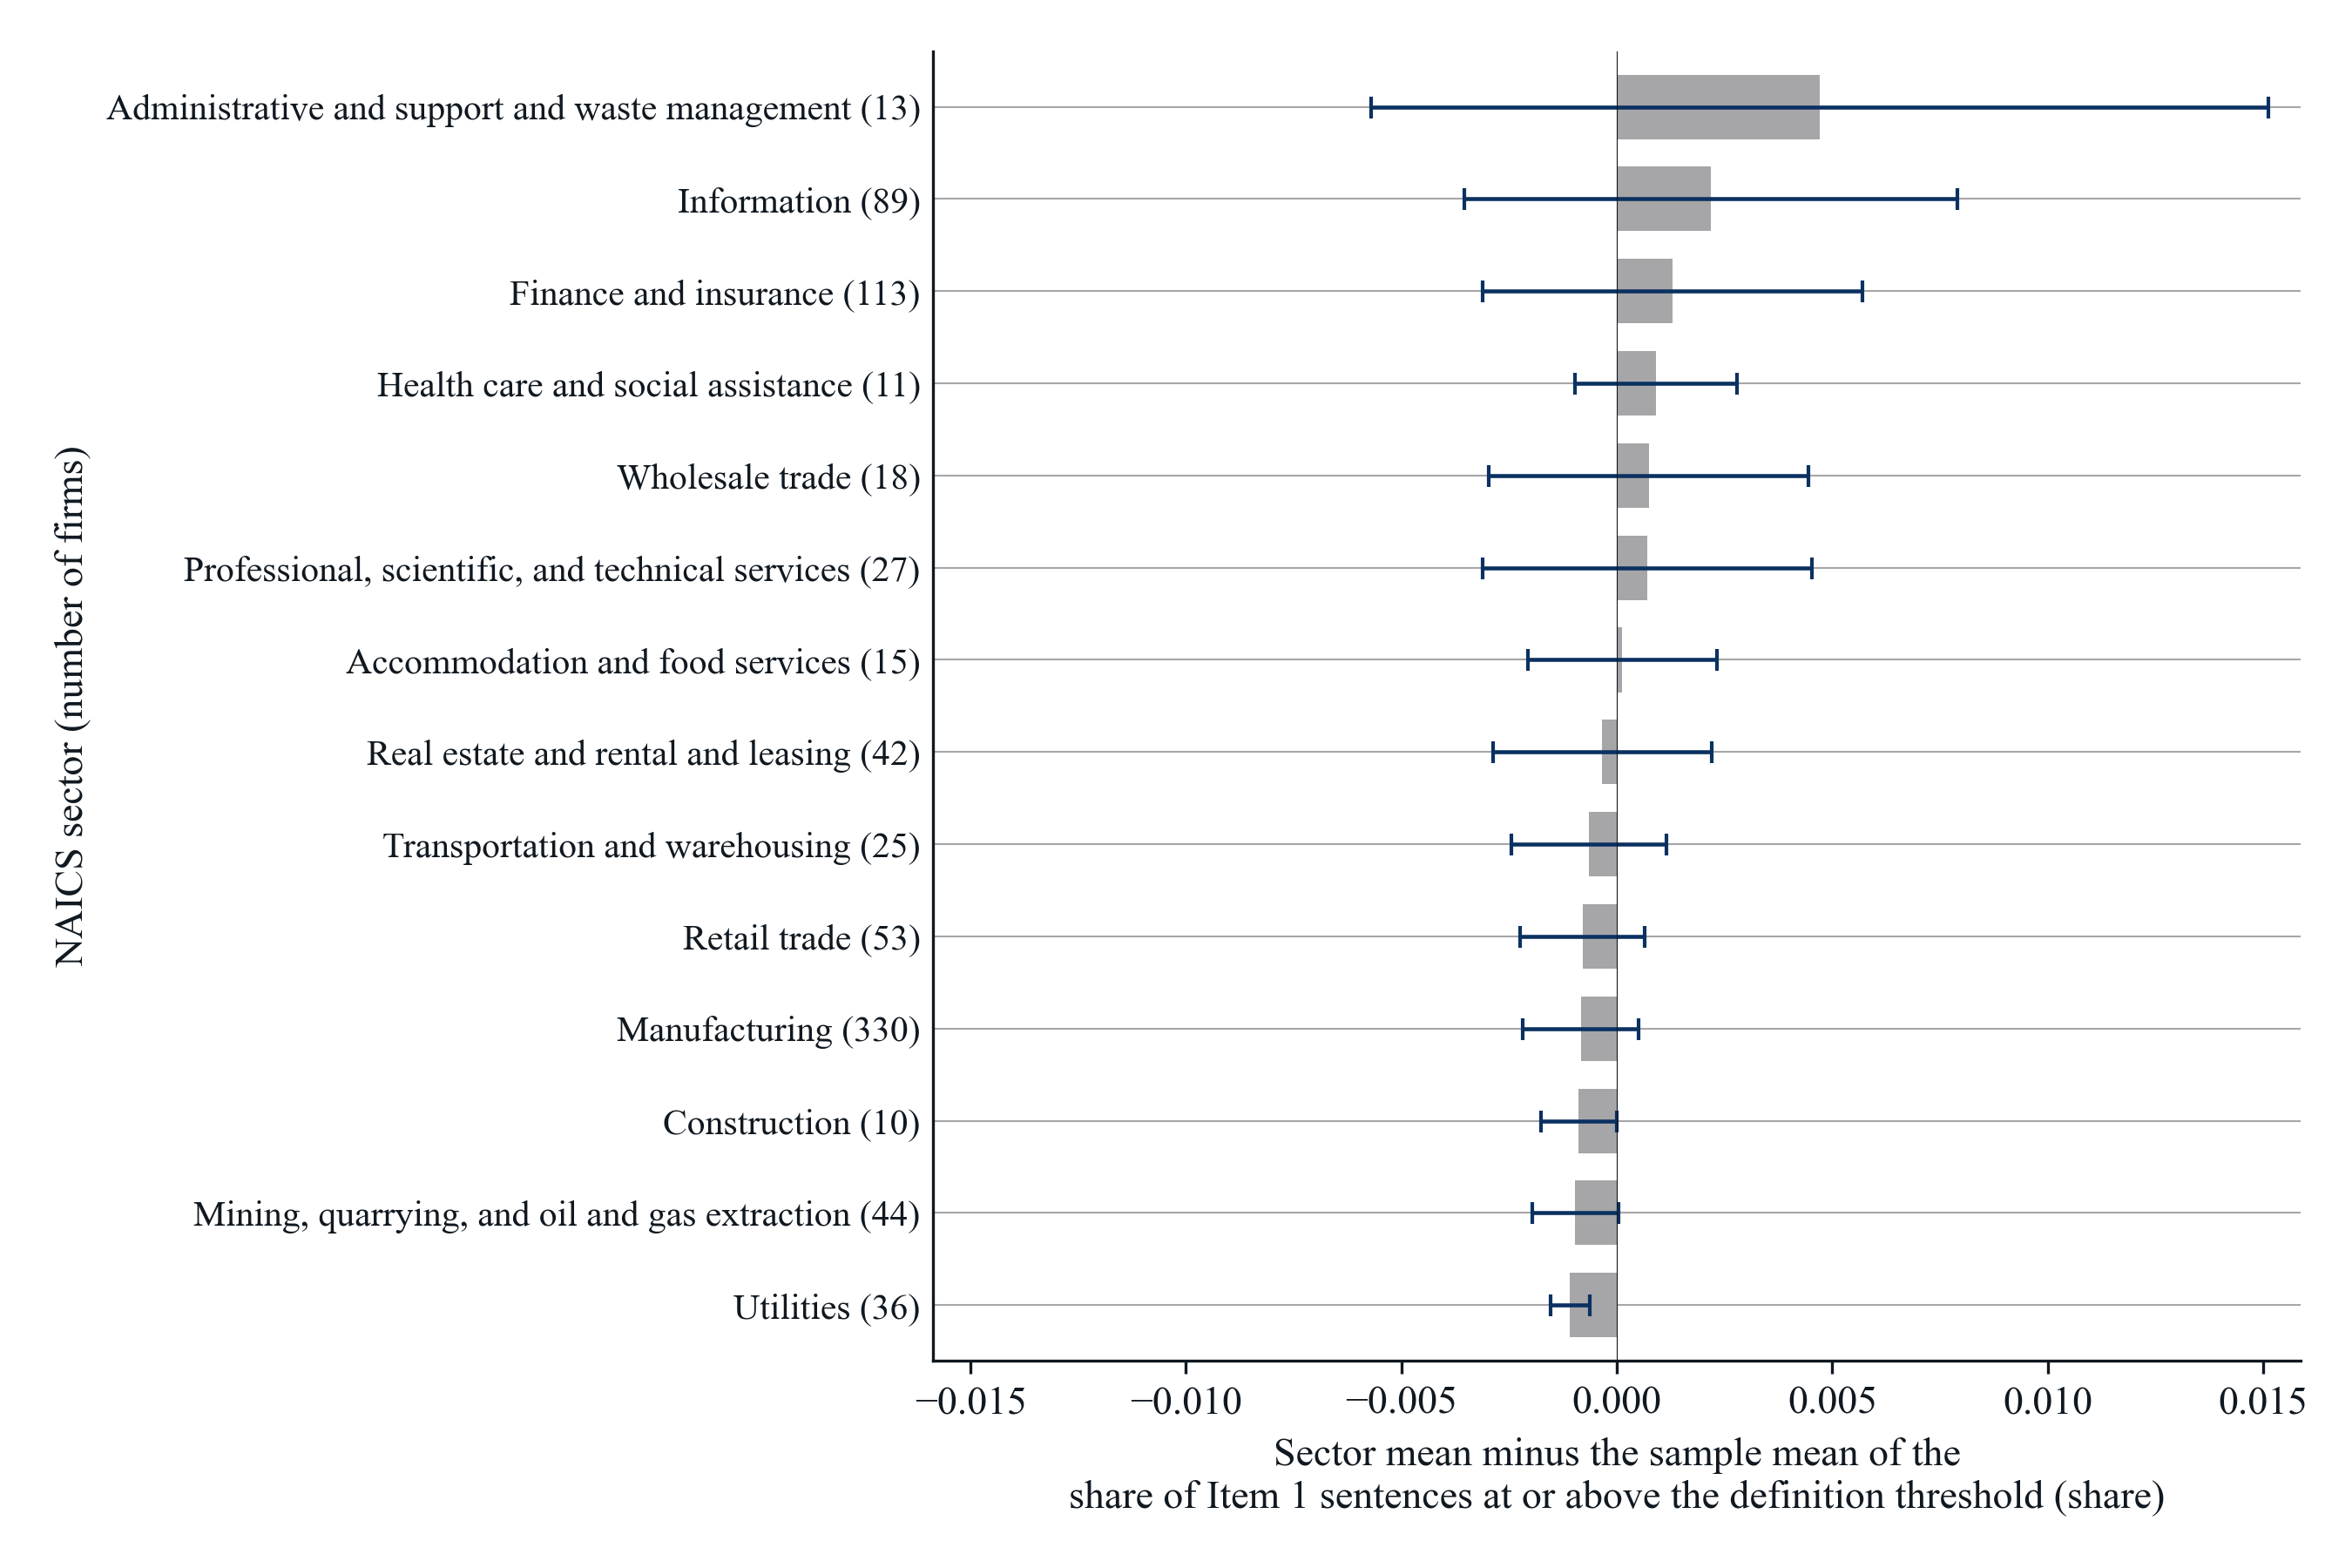

*Notes*: Each bar is the sector mean minus the mean over all 841 firms of the three-year sample (fiscal years 2010, 2015, and 2020) of the firm score, which is the share of the firm's Item 1 sentences whose cosine with the topic definition is at or above 0.67, compared with the topic definition of Topic 68, consumer data privacy legislation. Zero is the sample mean, 0.0012; bars to the right are sectors above it and bars to the left sectors below it. The error bar spans one standard deviation of the firm scores within the sector on each side of the sector mean, the within-industry variation across firms. Sectors are the two-digit NAICS sectors of the firms' Compustat NAICS codes, with manufacturing (31 to 33), retail trade (44 to 45), and transportation and warehousing (48 to 49) each taken as one sector; the number of firms in each sector is in parentheses. Sectors with fewer than 5 firms are left out: Arts, entertainment, and recreation (4 firms); Unclassified (4 firms); Educational services (3 firms); Other services (2 firms); Agriculture, forestry, fishing and hunting (2 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 3. Share of Firms with a Matched Sentence by NAICS Sector Relative to the Sample Mean, with the Centroid Vector**

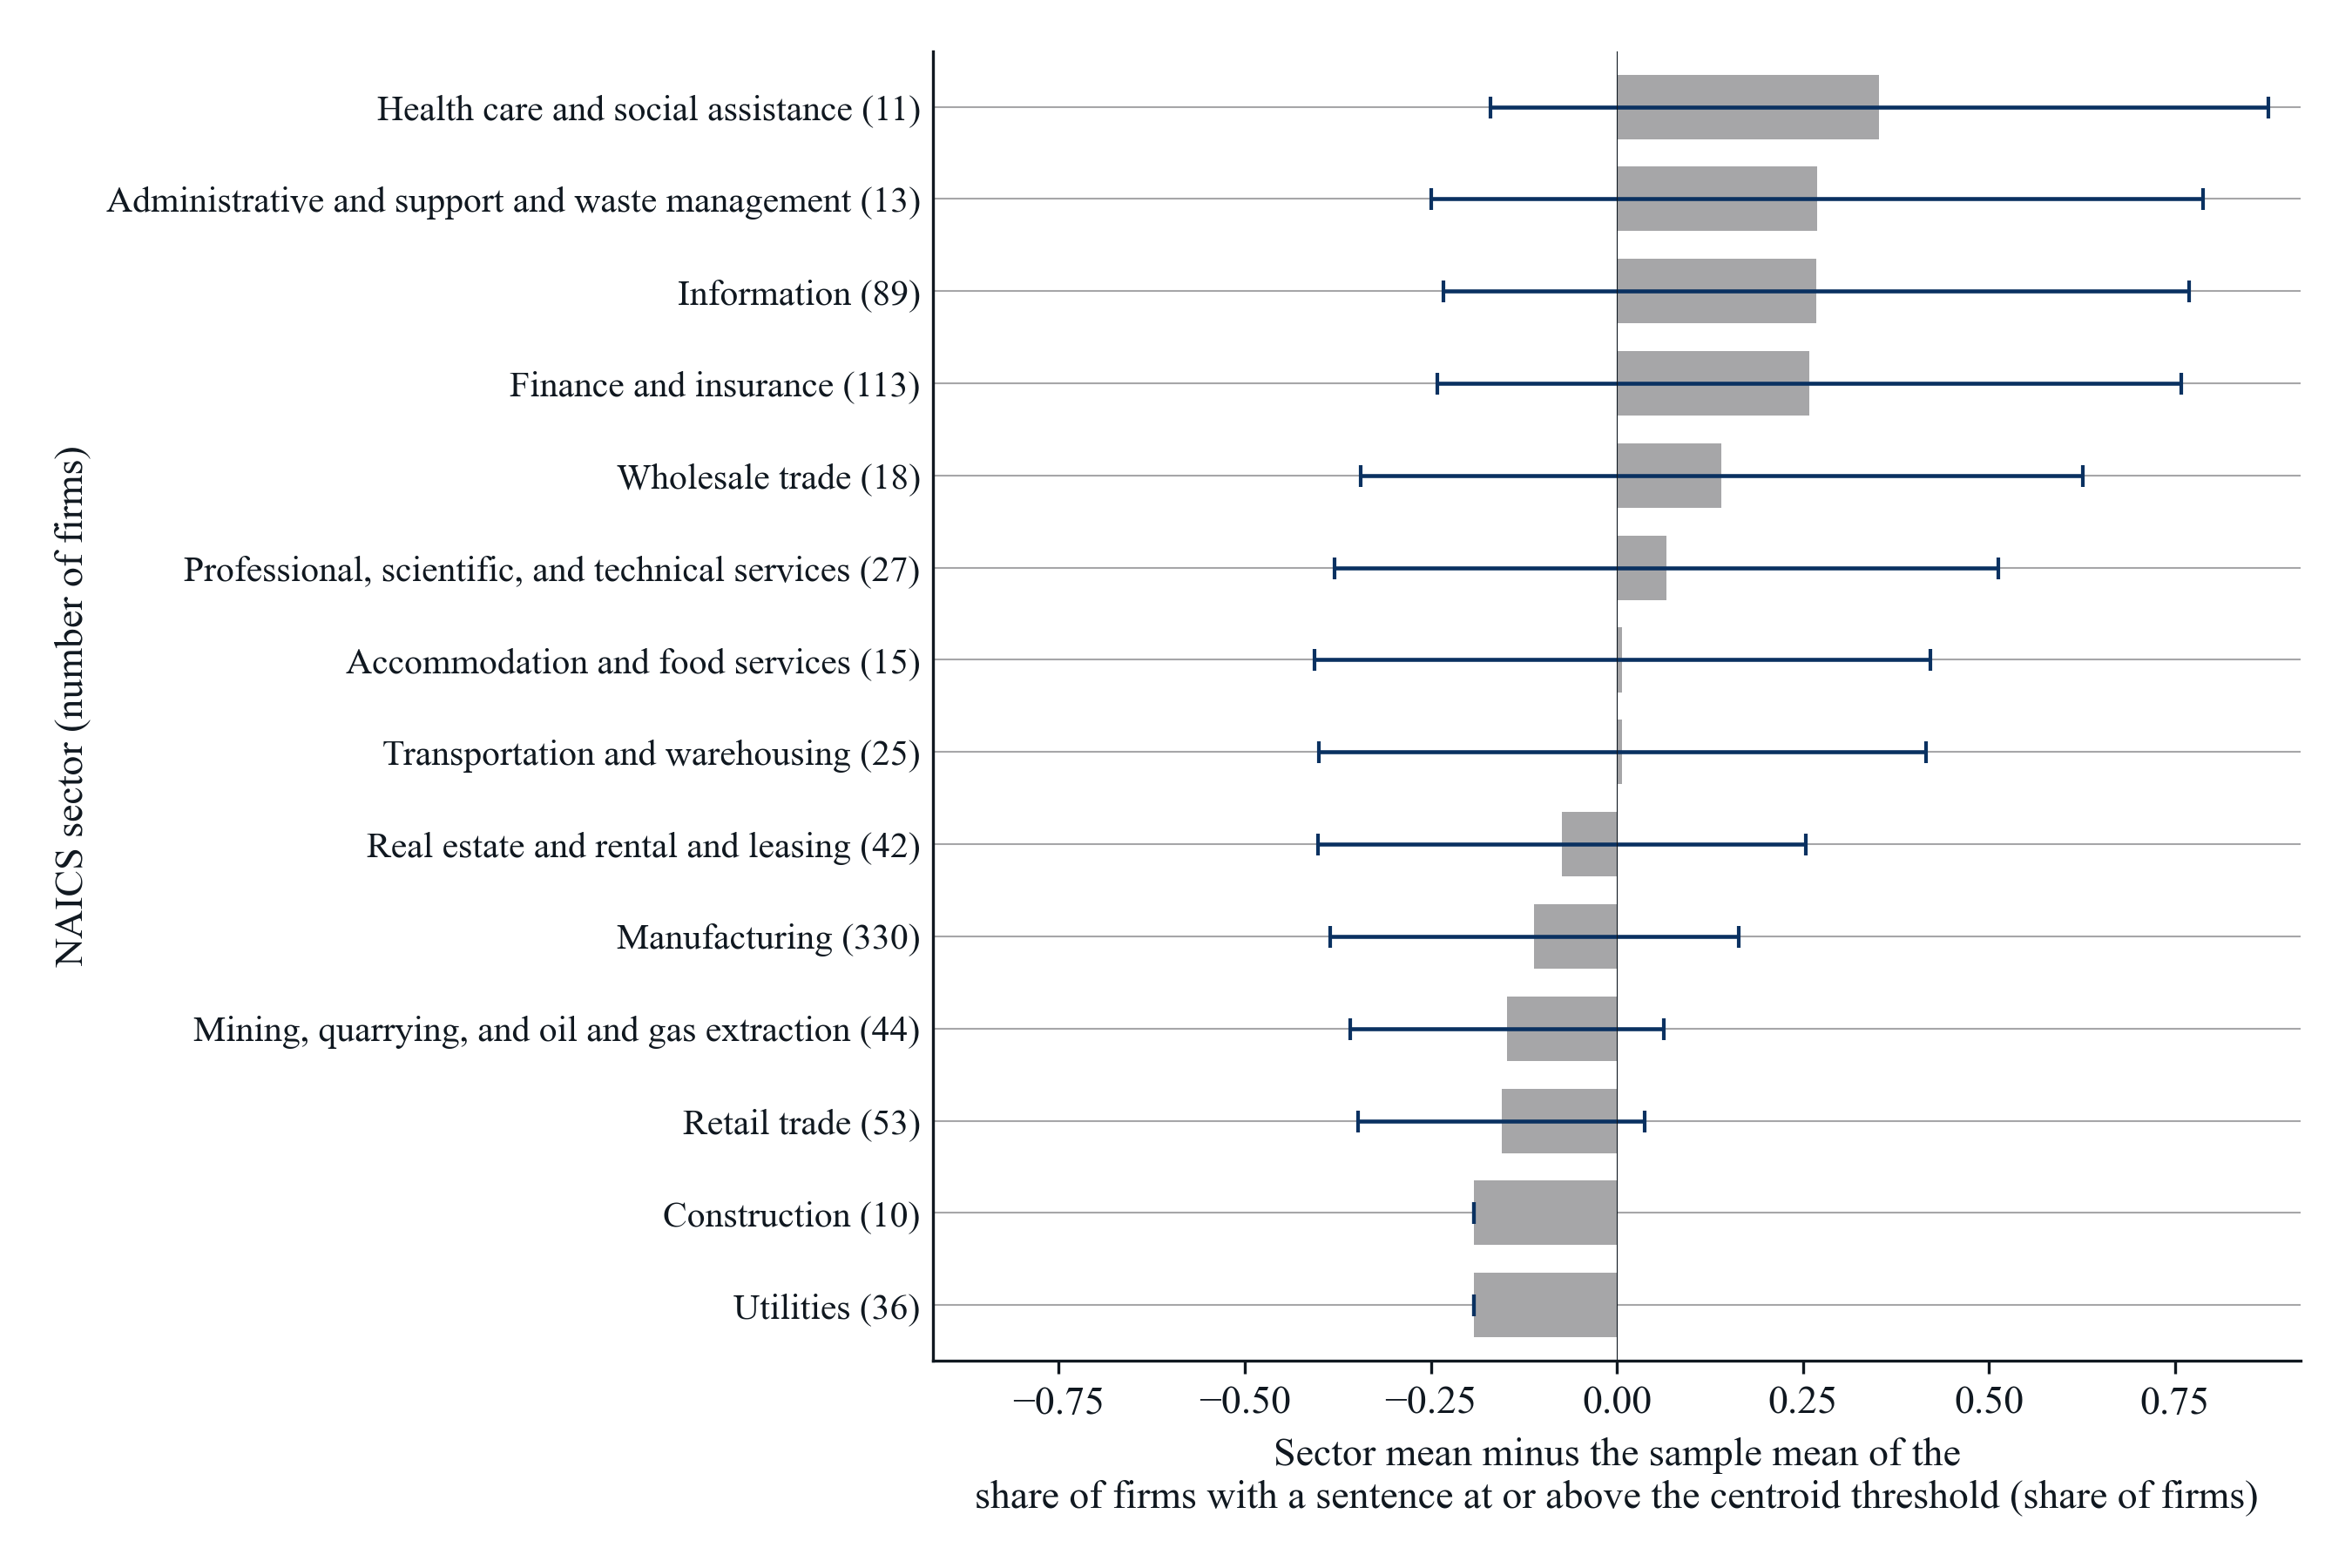

*Notes*: Each bar is the sector mean minus the mean over all 841 firms of the three-year sample (fiscal years 2010, 2015, and 2020) of the firm score, which is an indicator for the firm having at least one Item 1 sentence whose cosine with the statement centroid is at or above 0.75, so the sector mean is the share of such firms, compared with the statement centroid of Topic 68, consumer data privacy legislation. Zero is the sample mean, 0.1926; bars to the right are sectors above it and bars to the left sectors below it. The error bar spans one standard deviation of the firm scores within the sector on each side of the sector mean, the within-industry variation across firms. Sectors are the two-digit NAICS sectors of the firms' Compustat NAICS codes, with manufacturing (31 to 33), retail trade (44 to 45), and transportation and warehousing (48 to 49) each taken as one sector; the number of firms in each sector is in parentheses. Sectors with fewer than 5 firms are left out: Arts, entertainment, and recreation (4 firms); Unclassified (4 firms); Educational services (3 firms); Other services (2 firms); Agriculture, forestry, fishing and hunting (2 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 4. Share of Sentences by NAICS Sector Relative to the Sample Mean, with the Centroid Vector**

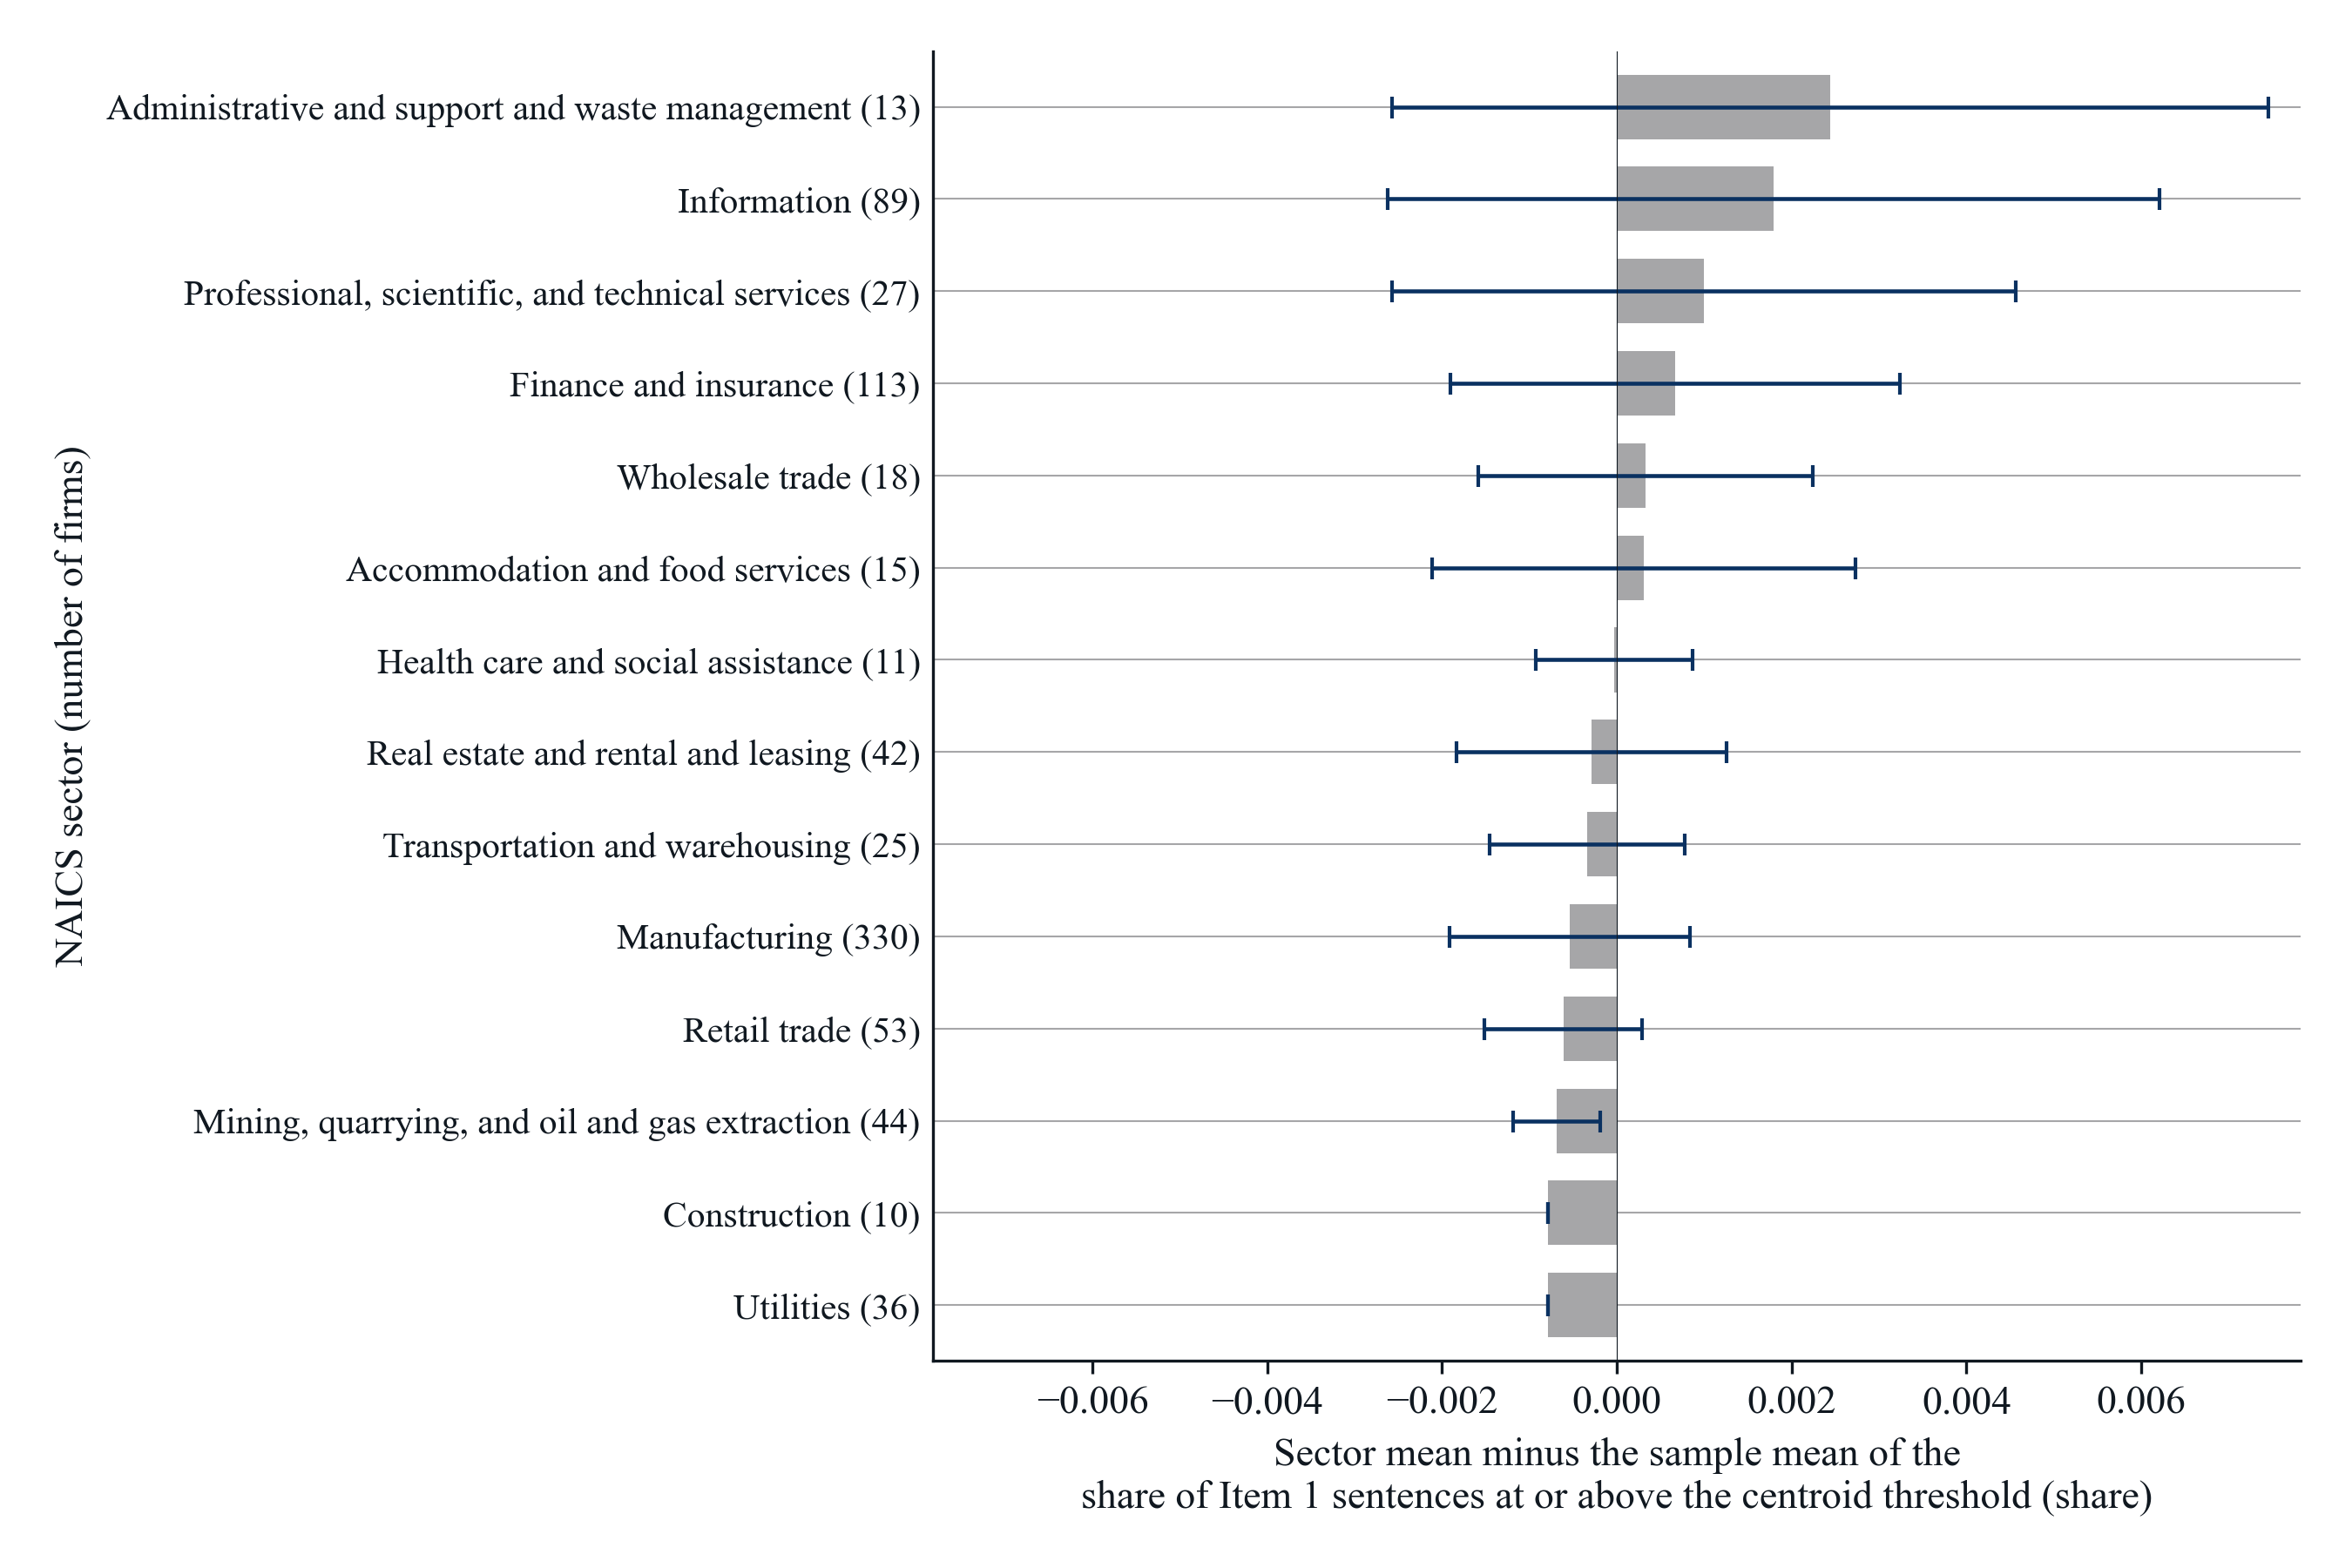

*Notes*: Each bar is the sector mean minus the mean over all 841 firms of the three-year sample (fiscal years 2010, 2015, and 2020) of the firm score, which is the share of the firm's Item 1 sentences whose cosine with the statement centroid is at or above 0.75, compared with the statement centroid of Topic 68, consumer data privacy legislation. Zero is the sample mean, 0.0008; bars to the right are sectors above it and bars to the left sectors below it. The error bar spans one standard deviation of the firm scores within the sector on each side of the sector mean, the within-industry variation across firms. Sectors are the two-digit NAICS sectors of the firms' Compustat NAICS codes, with manufacturing (31 to 33), retail trade (44 to 45), and transportation and warehousing (48 to 49) each taken as one sector; the number of firms in each sector is in parentheses. Sectors with fewer than 5 firms are left out: Arts, entertainment, and recreation (4 firms); Unclassified (4 firms); Educational services (3 firms); Other services (2 firms); Agriculture, forestry, fishing and hunting (2 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 5. Firm Summary Cosine by NAICS Sector Relative to the Sample Mean, with the Definition Vector**

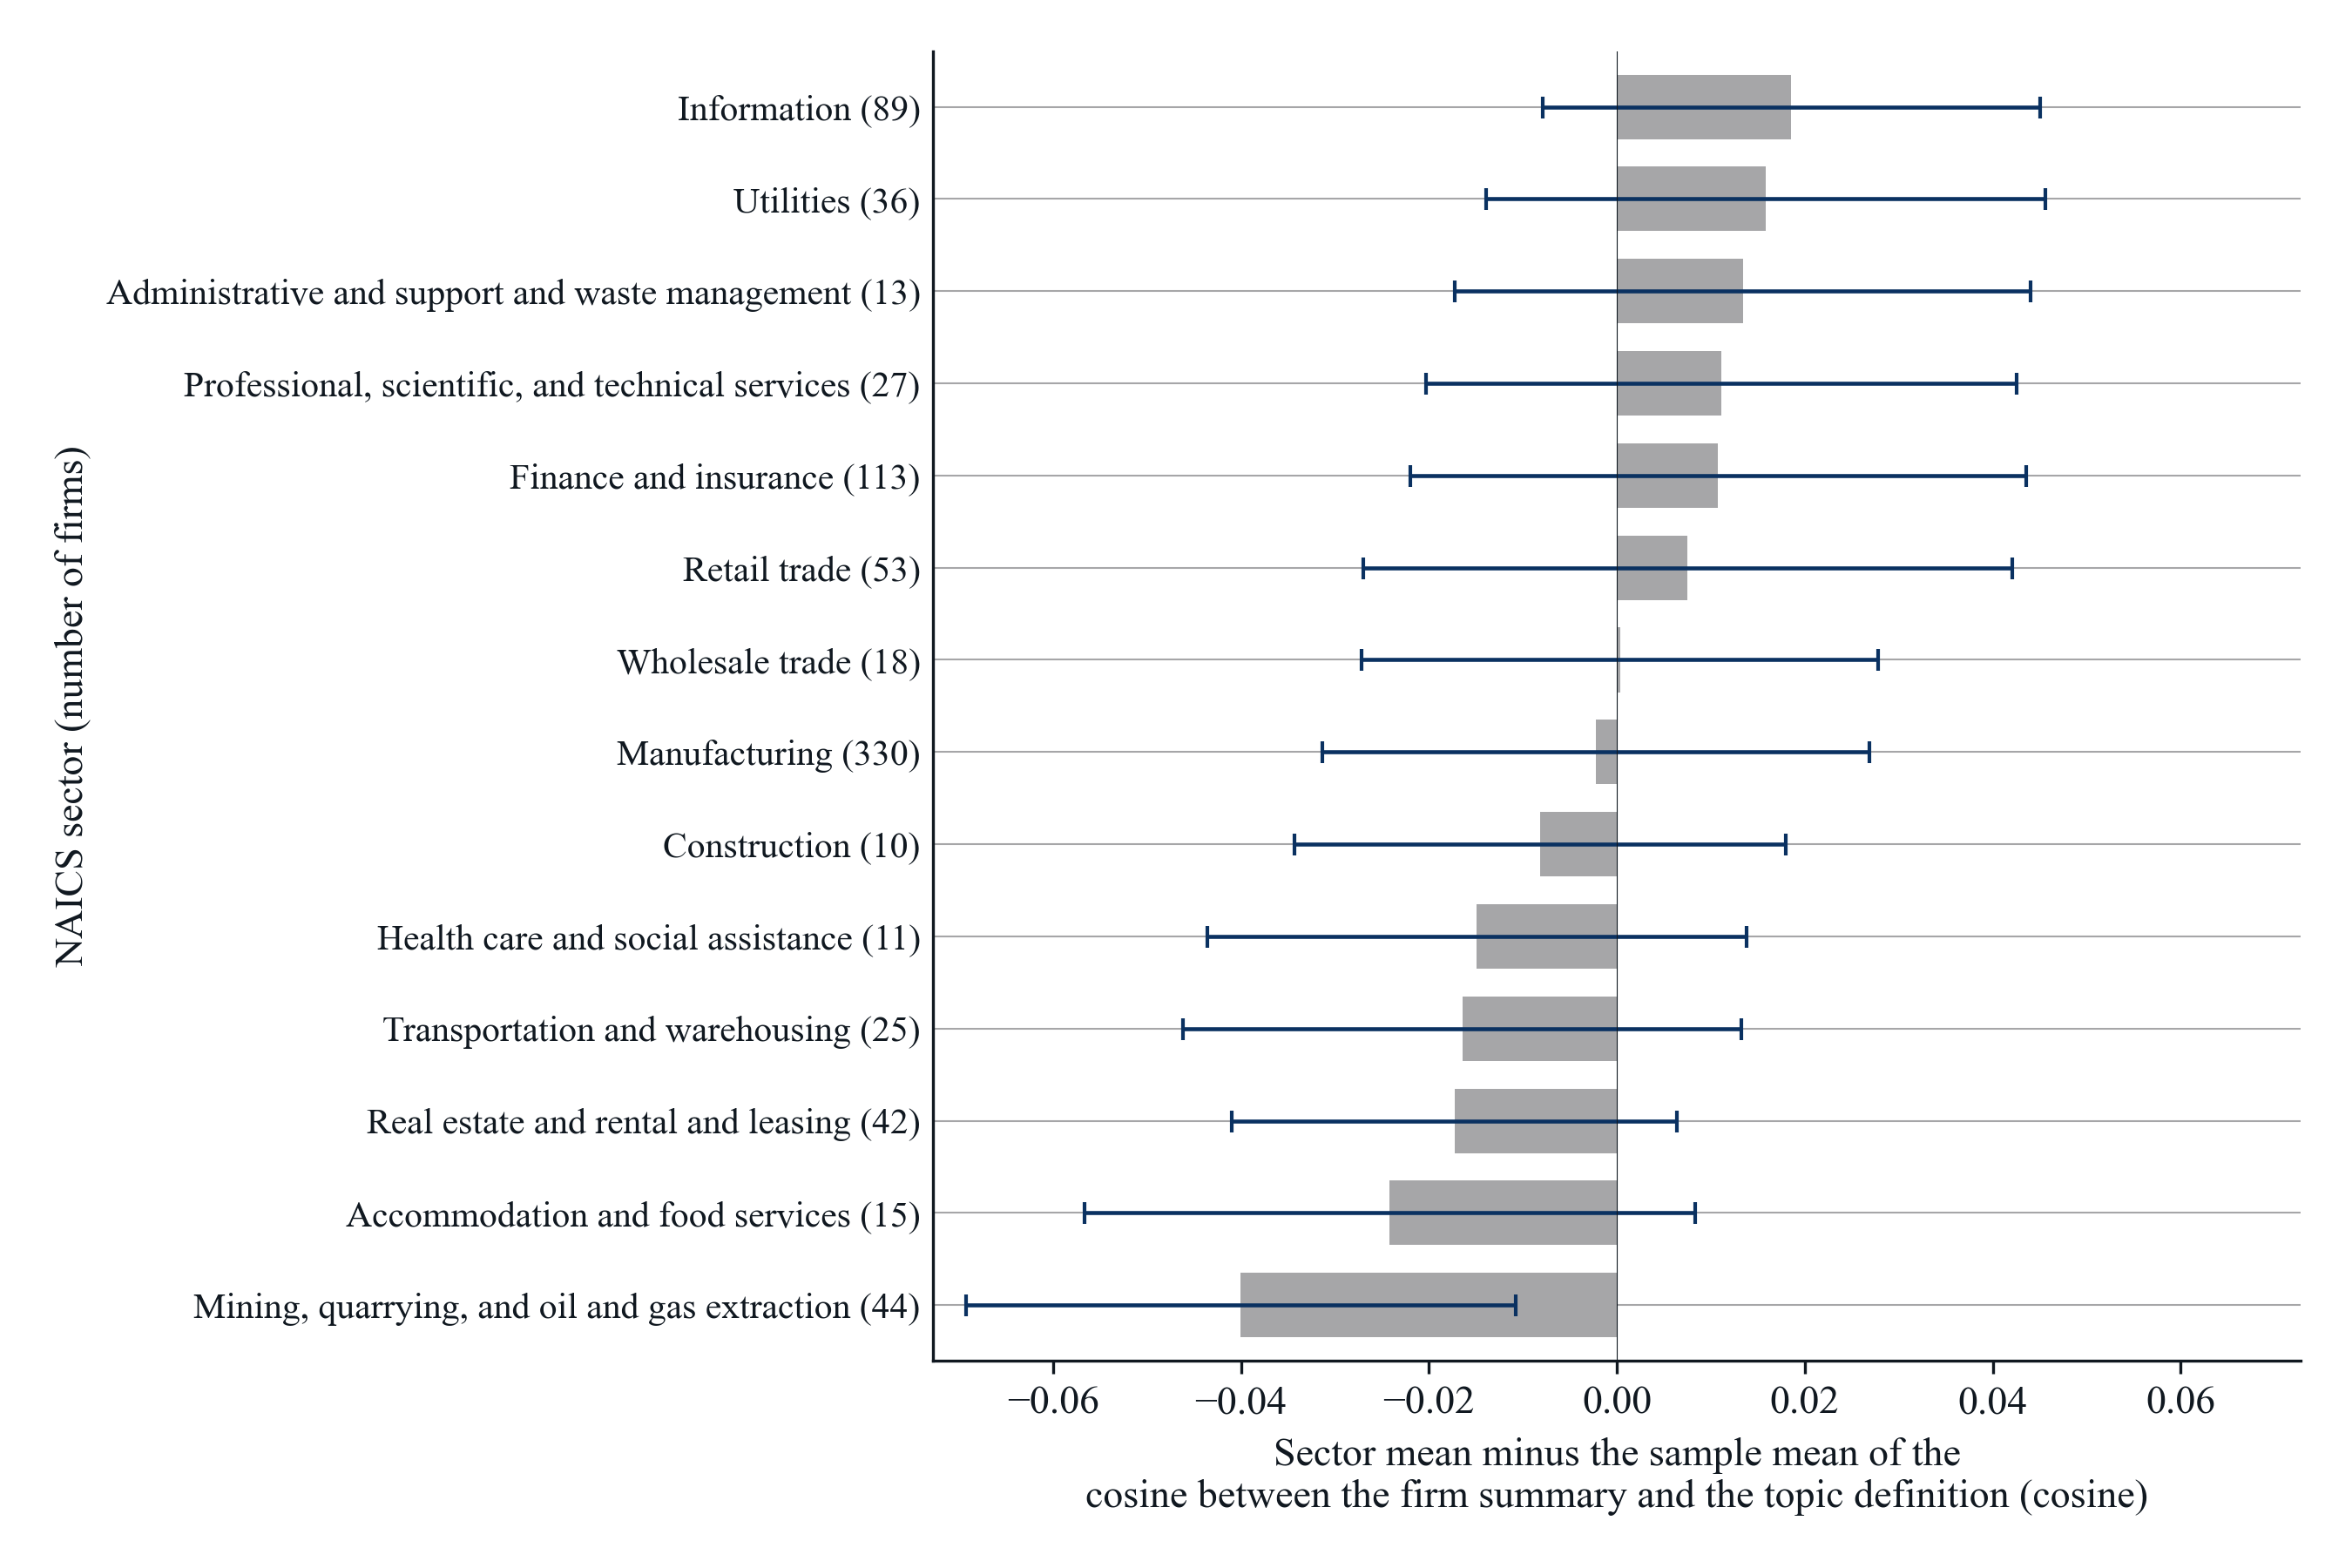

*Notes*: Each bar is the sector mean minus the mean over all 841 firms of the three-year sample (fiscal years 2010, 2015, and 2020) of the firm score, which is the cosine between the firm's Item 1 summary and the topic definition, compared with the topic definition of Topic 68, consumer data privacy legislation. Zero is the sample mean, 0.4313; bars to the right are sectors above it and bars to the left sectors below it. The error bar spans one standard deviation of the firm scores within the sector on each side of the sector mean, the within-industry variation across firms. Sectors are the two-digit NAICS sectors of the firms' Compustat NAICS codes, with manufacturing (31 to 33), retail trade (44 to 45), and transportation and warehousing (48 to 49) each taken as one sector; the number of firms in each sector is in parentheses. Sectors with fewer than 5 firms are left out: Arts, entertainment, and recreation (4 firms); Unclassified (4 firms); Educational services (3 firms); Other services (2 firms); Agriculture, forestry, fishing and hunting (2 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 6. Yearly Summary Mean Cosine by NAICS Sector Relative to the Sample Mean, with the Definition Vector**

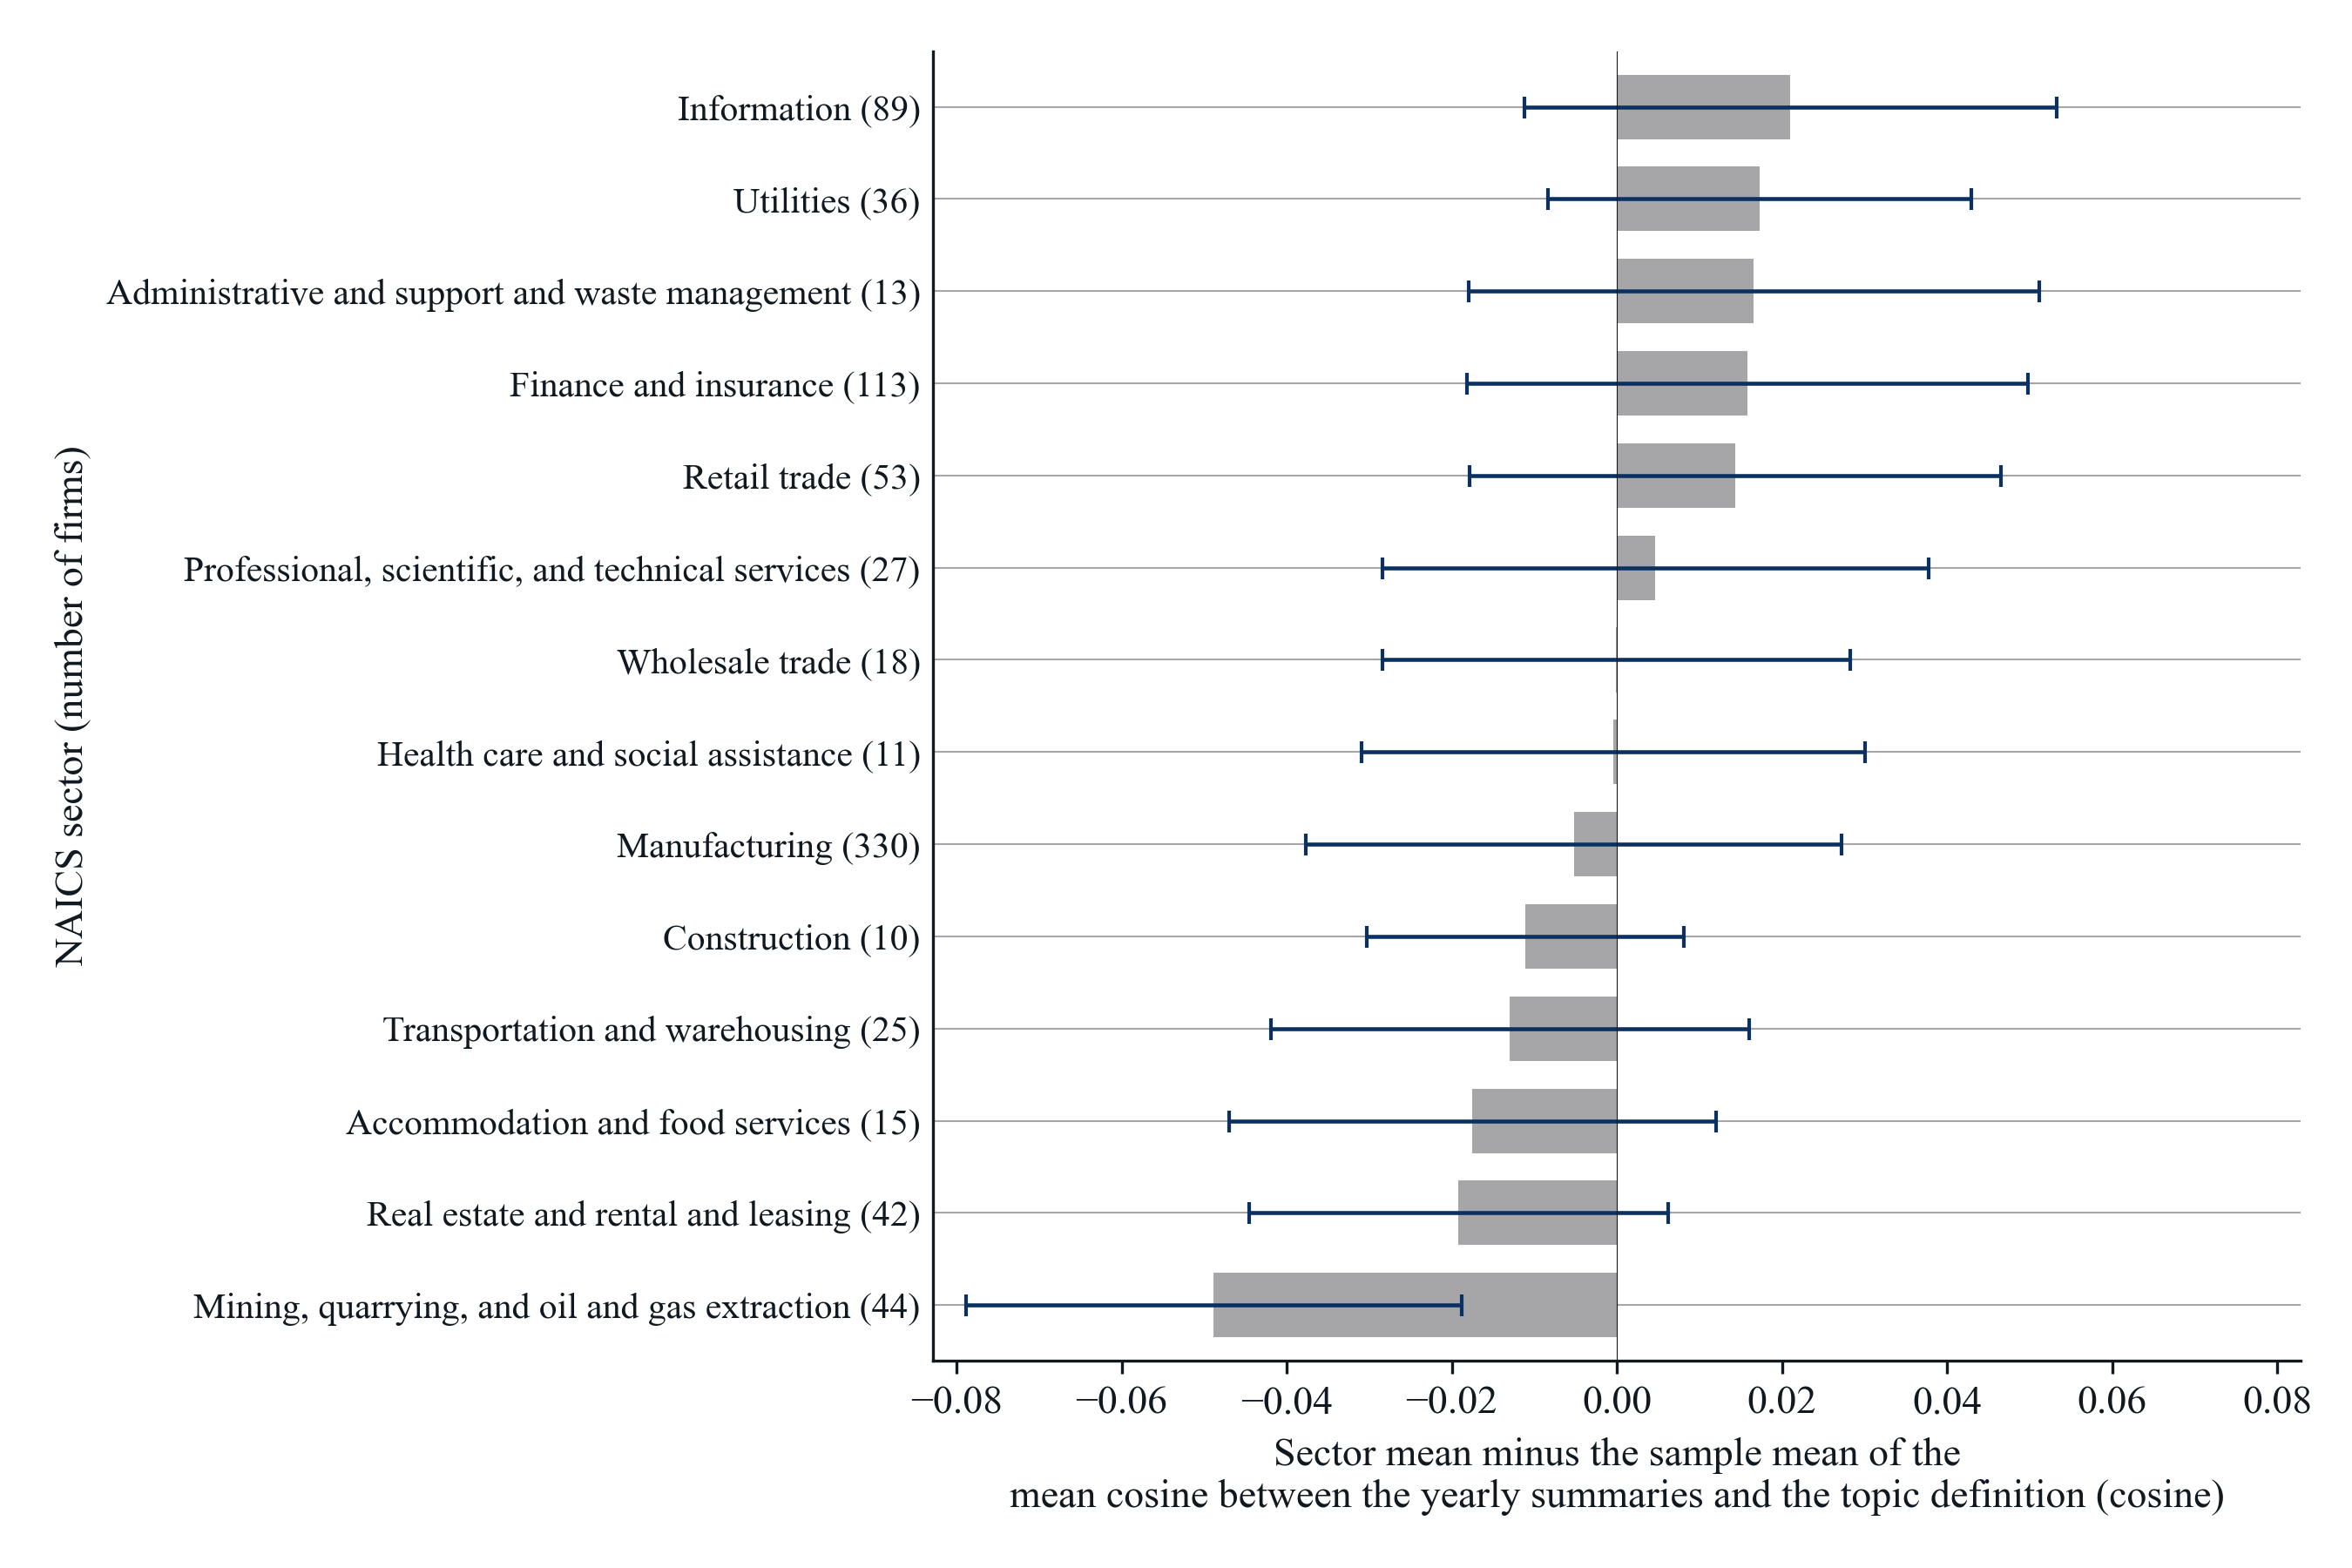

*Notes*: Each bar is the sector mean minus the mean over all 841 firms of the three-year sample (fiscal years 2010, 2015, and 2020) of the firm score, which is the firm's average cosine between its yearly Item 1 summaries and the topic definition, compared with the topic definition of Topic 68, consumer data privacy legislation. Zero is the sample mean, 0.4333; bars to the right are sectors above it and bars to the left sectors below it. The error bar spans one standard deviation of the firm scores within the sector on each side of the sector mean, the within-industry variation across firms. Sectors are the two-digit NAICS sectors of the firms' Compustat NAICS codes, with manufacturing (31 to 33), retail trade (44 to 45), and transportation and warehousing (48 to 49) each taken as one sector; the number of firms in each sector is in parentheses. Sectors with fewer than 5 firms are left out: Arts, entertainment, and recreation (4 firms); Unclassified (4 firms); Educational services (3 firms); Other services (2 firms); Agriculture, forestry, fishing and hunting (2 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 7. Firm Summary Cosine by NAICS Sector Relative to the Sample Mean, with the Centroid Vector**

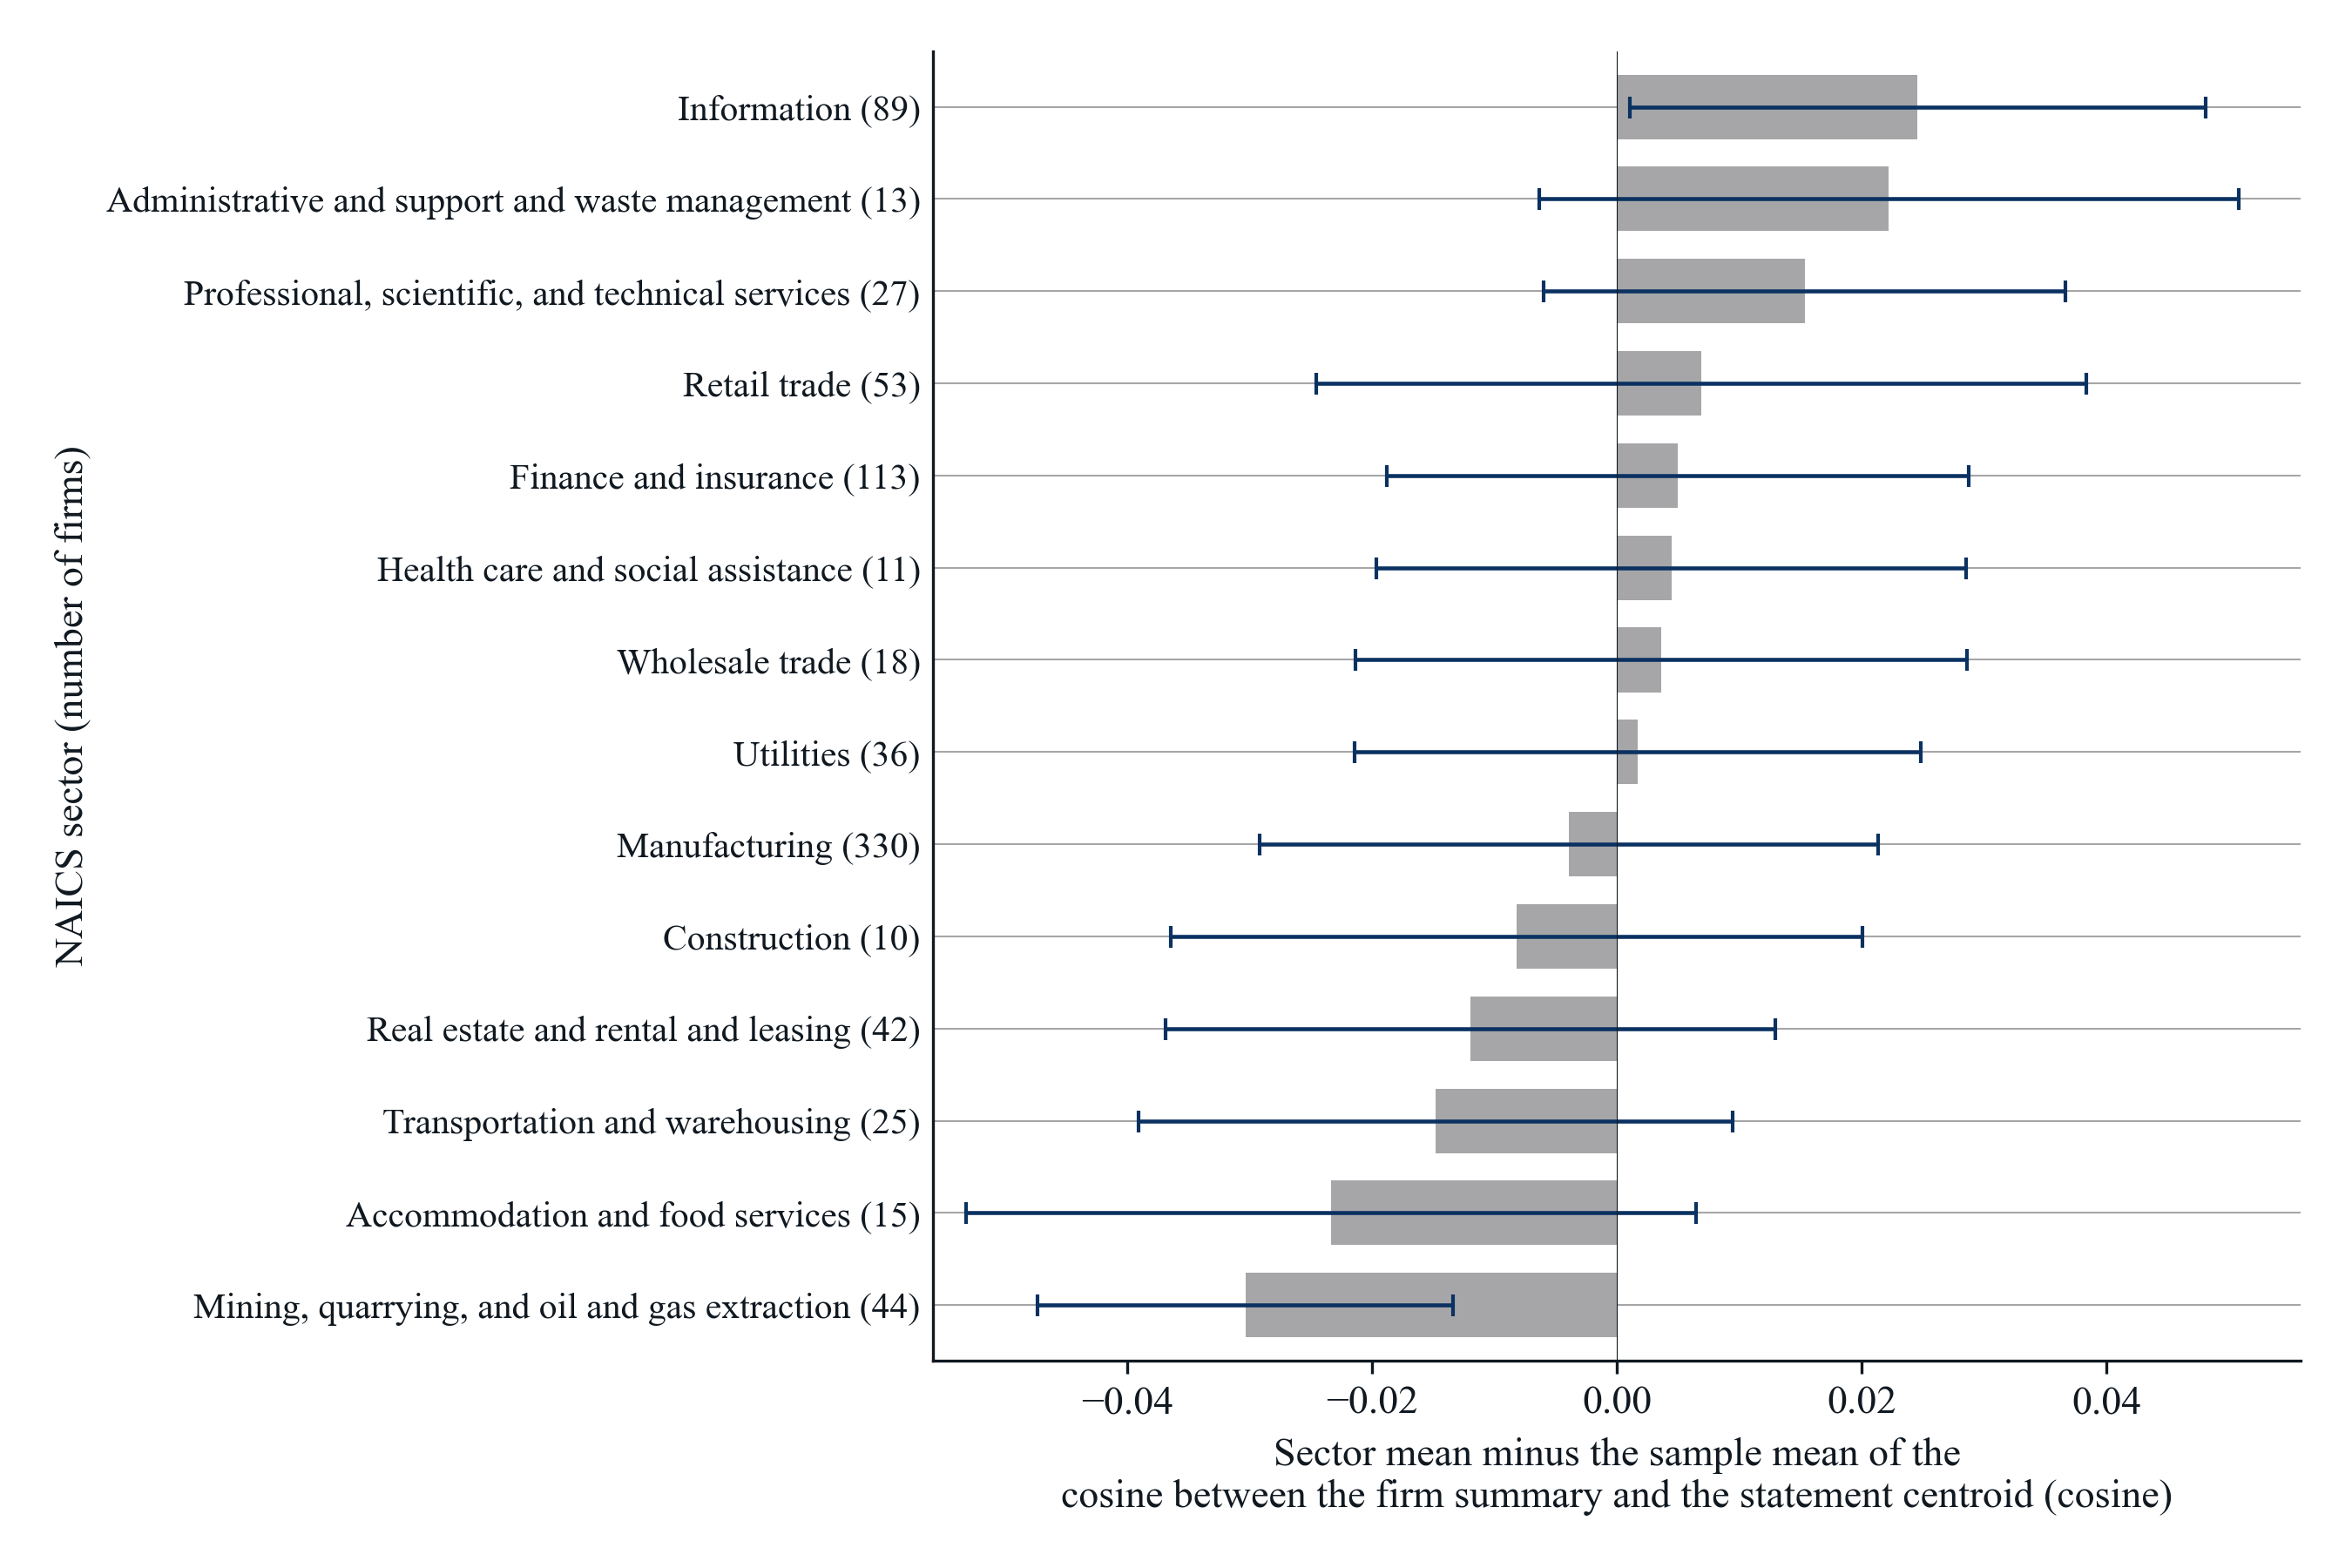

*Notes*: Each bar is the sector mean minus the mean over all 841 firms of the three-year sample (fiscal years 2010, 2015, and 2020) of the firm score, which is the cosine between the firm's Item 1 summary and the centroid of the Topic 68 hearing statements, compared with the statement centroid of Topic 68, consumer data privacy legislation. Zero is the sample mean, 0.5032; bars to the right are sectors above it and bars to the left sectors below it. The error bar spans one standard deviation of the firm scores within the sector on each side of the sector mean, the within-industry variation across firms. Sectors are the two-digit NAICS sectors of the firms' Compustat NAICS codes, with manufacturing (31 to 33), retail trade (44 to 45), and transportation and warehousing (48 to 49) each taken as one sector; the number of firms in each sector is in parentheses. Sectors with fewer than 5 firms are left out: Arts, entertainment, and recreation (4 firms); Unclassified (4 firms); Educational services (3 firms); Other services (2 firms); Agriculture, forestry, fishing and hunting (2 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 8. Yearly Summary Mean Cosine by NAICS Sector Relative to the Sample Mean, with the Centroid Vector**

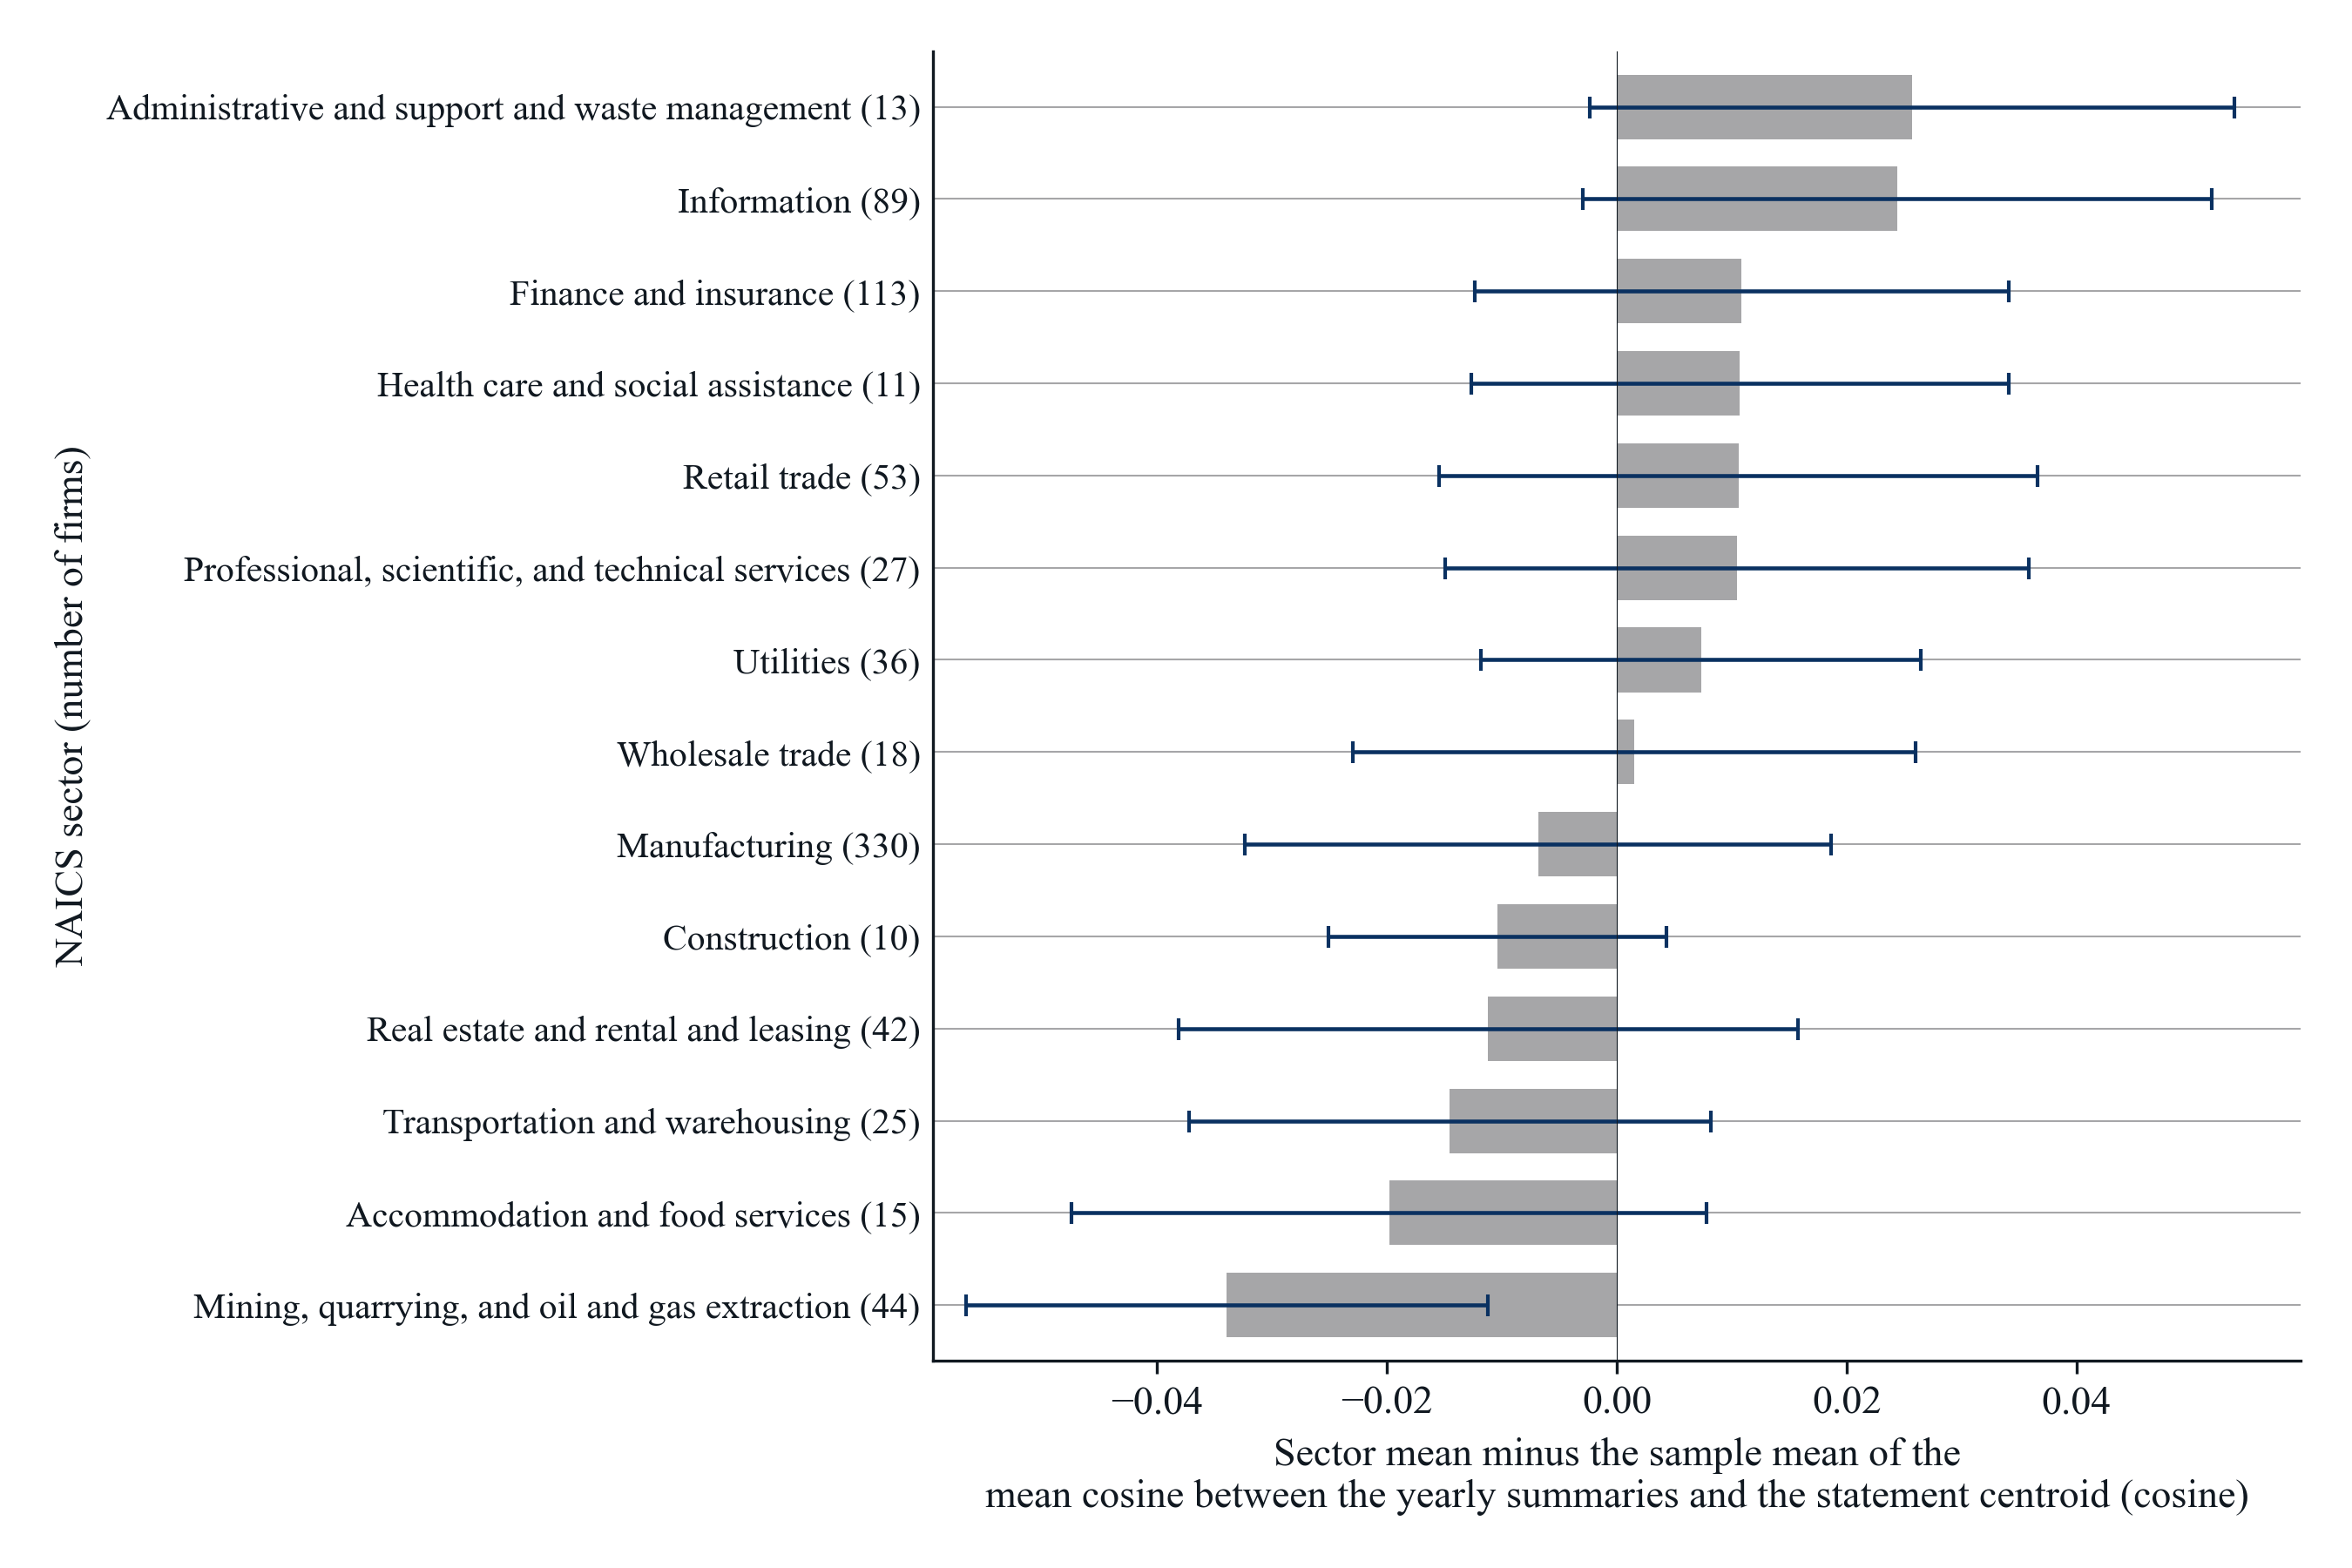

*Notes*: Each bar is the sector mean minus the mean over all 841 firms of the three-year sample (fiscal years 2010, 2015, and 2020) of the firm score, which is the firm's average cosine between its yearly Item 1 summaries and the centroid of the Topic 68 hearing statements, compared with the statement centroid of Topic 68, consumer data privacy legislation. Zero is the sample mean, 0.5011; bars to the right are sectors above it and bars to the left sectors below it. The error bar spans one standard deviation of the firm scores within the sector on each side of the sector mean, the within-industry variation across firms. Sectors are the two-digit NAICS sectors of the firms' Compustat NAICS codes, with manufacturing (31 to 33), retail trade (44 to 45), and transportation and warehousing (48 to 49) each taken as one sector; the number of firms in each sector is in parentheses. Sectors with fewer than 5 firms are left out: Arts, entertainment, and recreation (4 firms); Unclassified (4 firms); Educational services (3 firms); Other services (2 firms); Agriculture, forestry, fishing and hunting (2 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 9. Firm Summary Cosine by NAICS Sector Relative to the Sample Mean, with the Policy Summary Vector**

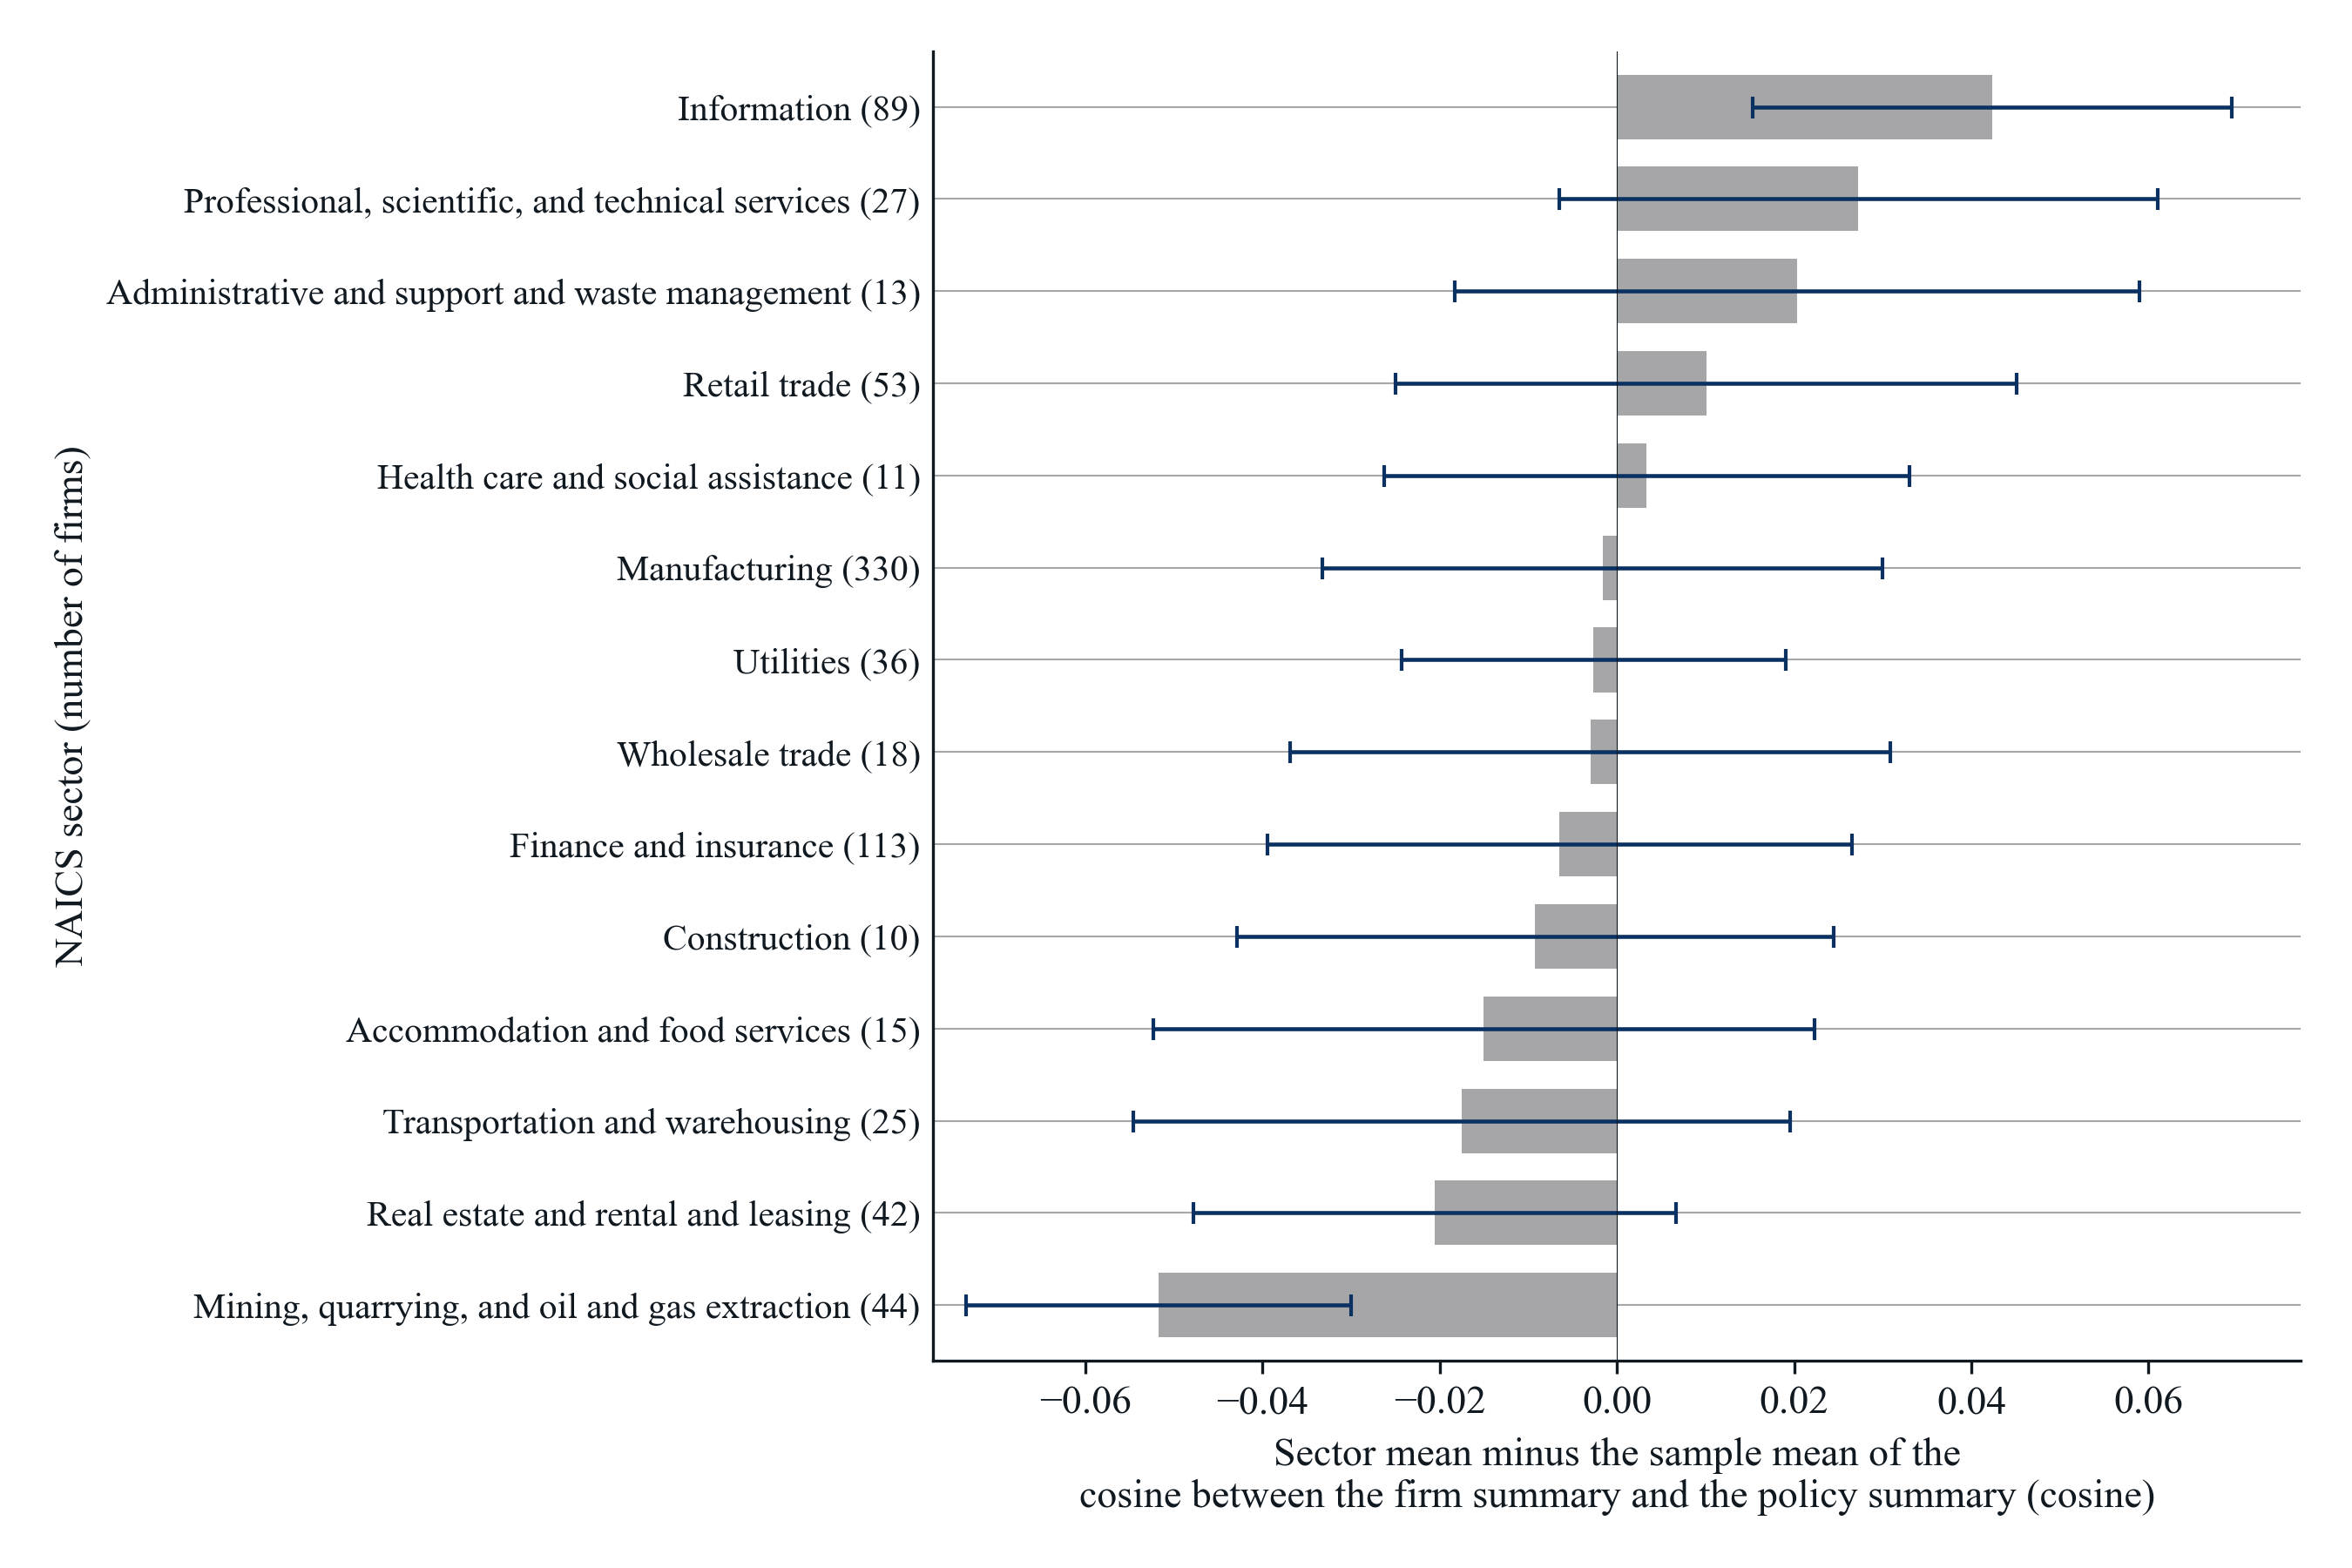

*Notes*: Each bar is the sector mean minus the mean over all 841 firms of the three-year sample (fiscal years 2010, 2015, and 2020) of the firm score, which is the cosine between the firm's Item 1 summary and the policy summary of the Topic 68 hearing statements, compared with the policy summary of Topic 68, consumer data privacy legislation. Zero is the sample mean, 0.5143; bars to the right are sectors above it and bars to the left sectors below it. The error bar spans one standard deviation of the firm scores within the sector on each side of the sector mean, the within-industry variation across firms. Sectors are the two-digit NAICS sectors of the firms' Compustat NAICS codes, with manufacturing (31 to 33), retail trade (44 to 45), and transportation and warehousing (48 to 49) each taken as one sector; the number of firms in each sector is in parentheses. Sectors with fewer than 5 firms are left out: Arts, entertainment, and recreation (4 firms); Unclassified (4 firms); Educational services (3 firms); Other services (2 firms); Agriculture, forestry, fishing and hunting (2 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 10. Yearly Summary Mean Cosine by NAICS Sector Relative to the Sample Mean, with the Policy Summary Vector**

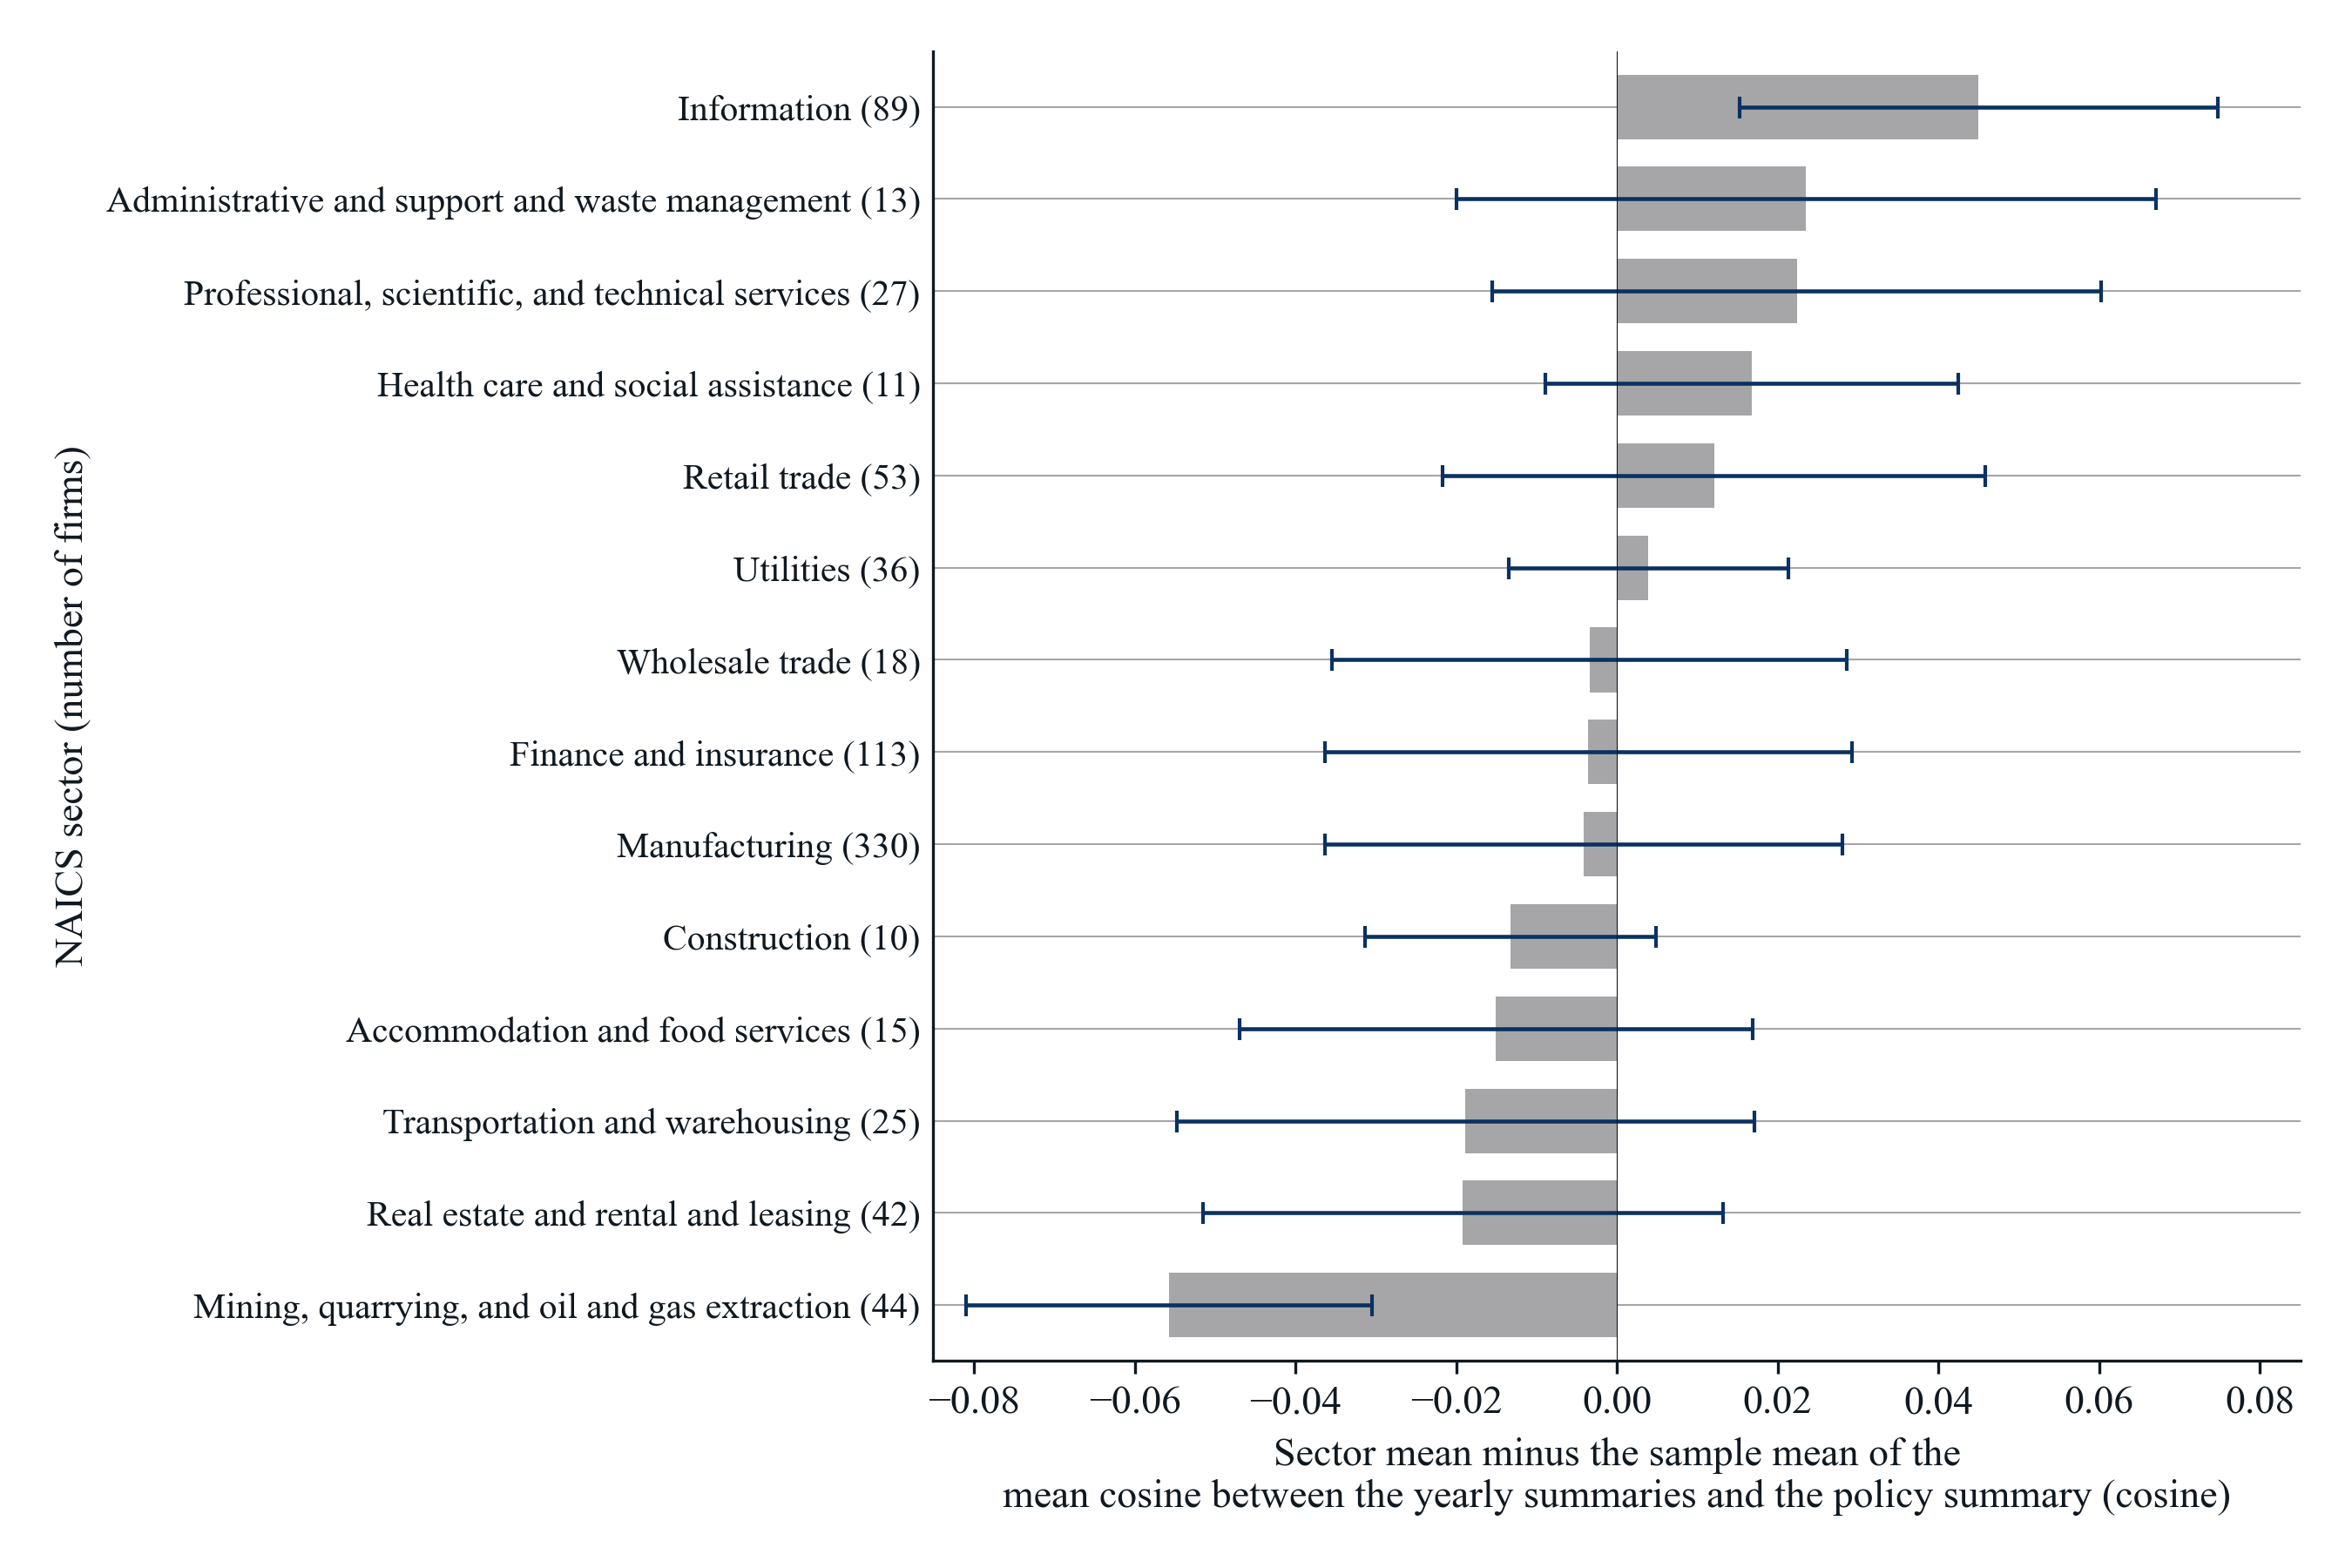

*Notes*: Each bar is the sector mean minus the mean over all 841 firms of the three-year sample (fiscal years 2010, 2015, and 2020) of the firm score, which is the firm's average cosine between its yearly Item 1 summaries and the policy summary of the Topic 68 hearing statements, compared with the policy summary of Topic 68, consumer data privacy legislation. Zero is the sample mean, 0.5078; bars to the right are sectors above it and bars to the left sectors below it. The error bar spans one standard deviation of the firm scores within the sector on each side of the sector mean, the within-industry variation across firms. Sectors are the two-digit NAICS sectors of the firms' Compustat NAICS codes, with manufacturing (31 to 33), retail trade (44 to 45), and transportation and warehousing (48 to 49) each taken as one sector; the number of firms in each sector is in parentheses. Sectors with fewer than 5 firms are left out: Arts, entertainment, and recreation (4 firms); Unclassified (4 firms); Educational services (3 firms); Other services (2 firms); Agriculture, forestry, fishing and hunting (2 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [7]:
MEASURE_TITLES = {"binary": "Share of Firms with a Matched Sentence", "share": "Share of Sentences", "firm_summary": "Firm Summary Cosine", "yearly_mean": "Yearly Summary Mean Cosine"}
VECTOR_TITLES = {"definition": "Definition Vector", "centroid": "Centroid Vector", "policy_summary": "Policy Summary Vector"}
for figure_number, figure_name, measure_id, notes in figure_records:
    method, vector, measure = [part.strip() for part in measure_id.split("|")]
    display(Markdown(f"**Figure {figure_number}. {MEASURE_TITLES[measure]} by NAICS Sector Relative to the Sample Mean, with the {VECTOR_TITLES[vector]}**"))
    display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
    display(Markdown(f"*Notes*: {notes}"))
    display(Markdown(f"*Source*: {SOURCE}."))
